# Overview {#sec-pca}




In [87]:
#| code-fold: true
#| code-summary: Code to prepare the environment

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import plotly.graph_objects as go

curfolder = os.getcwd()

# This is where our features live
features = os.path.join(curfolder, 'Datasets')
df = pd.read_csv(os.path.join(features, 'sapiens_features_noconcept_noLP.csv'))

df.head()

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_jerk,fine__coordination__finger_independence,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.308611,0.041215,0.092766,0.460921,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
1,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,1.688551,0.272164,-0.495235,0.112665,2.952784,GP01_BODEN,GP01,Gesture,BODEN,GP01
2,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,1.043274,0.612119,0.658854,0.218333,3.166920,GP01_BRIEF,GP01,Gesture,BRIEF,GP01
3,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,0.841905,0.172555,0.212377,0.088188,2.484640,GP01_BUERO,GP01,Gesture,BUERO,GP01
4,0.475486,0.705323,2.406980,NaN,1,0.212766,NaN,1.934251,2.938965,3.545241,...,0.551801,0.069693,1.557573,0.056993,2.567418,GP01_ENTSCHULDIGEN,GP01,Gesture,ENTSCHULDIGEN,GP01


In [88]:
# Show me proportion of missing values for each column
missing_values = df.isnull().mean() * 100
missing_values = missing_values[missing_values > 0]
print("Proportion of missing values in each column:")
missing_values

Proportion of missing values in each column:


gross__variability__arm_speed_peak_std    2.060738
gross__rhythm__arm_speed_mod_depth        2.060738
gross__variability__arm_acc_peak_std      0.108460
gross__rhythm__arm_acc_mod_depth          0.108460
dtype: float64

In [89]:
# how many rows if the df have any missing value
rows_with_missing_values = df[df.isnull().any(axis=1)]
print(f"Number of rows with missing values: {len(rows_with_missing_values)}")

# frop rows with missing values
df = df.dropna()
print(f"Number of rows after dropping missing values: {len(df)}")

Number of rows with missing values: 20
Number of rows after dropping missing values: 902


In [90]:
# how many rows in total?
total_rows = len(df)
print(f"Total number of rows: {total_rows}")

Total number of rows: 902


In [91]:
# how many columns is there
total_columns = len(df.columns)
print(f"Total number of columns: {total_columns}")

Total number of columns: 55


In [92]:
sampled_df = df.copy()

# how many unique groupID are there?
unique_groupIDs = sampled_df['groupID'].nunique()
print(f"Number of unique groupIDs: {unique_groupIDs}")

# get rid of LP group
sampled_df = sampled_df[sampled_df['groupID'] != 'LP']

# show them
print("Unique groupIDs:")
print(sampled_df['groupID'].unique())

Number of unique groupIDs: 4
Unique groupIDs:
<StringArray>
['Gesture', 'Sign', 'Learner_1', 'Learner_2']
Length: 4, dtype: str


In [93]:
sampled_df.head(50)

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_jerk,fine__coordination__finger_independence,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.308611,0.041215,0.092766,0.460921,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
1,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,1.688551,0.272164,-0.495235,0.112665,2.952784,GP01_BODEN,GP01,Gesture,BODEN,GP01
2,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,1.043274,0.612119,0.658854,0.218333,3.166920,GP01_BRIEF,GP01,Gesture,BRIEF,GP01
3,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,0.841905,0.172555,0.212377,0.088188,2.484640,GP01_BUERO,GP01,Gesture,BUERO,GP01
5,1.212209,0.936830,2.552069,0.800775,4,0.851064,2.255823,5.144732,3.626501,9.469993,...,0.522751,0.068401,1.439479,0.136125,2.798595,GP01_GIRAFFE,GP01,Gesture,GIRAFFE,GP01
6,0.934655,1.223187,3.778077,0.280621,2,0.425532,3.634399,3.988631,4.406260,11.715147,...,0.648607,0.103847,0.007529,0.035463,2.454548,GP01_GOTT,GP01,Gesture,GOTT,GP01
7,0.996011,0.991806,2.998488,0.691998,3,0.638298,2.488136,3.750782,3.669915,8.566859,...,0.906248,0.171889,-1.383385,0.094814,2.701999,GP01_HEMD,GP01,Gesture,HEMD,GP01
8,0.678410,0.565396,1.332935,0.610117,5,1.063830,1.112777,2.443043,1.835314,4.073219,...,0.511145,0.096810,-0.643728,0.323380,2.900614,GP01_SCHOKOLADE,GP01,Gesture,SCHOKOLADE,GP01
9,1.381503,0.704452,2.251771,0.460238,7,1.489362,1.552995,4.676557,2.103714,6.910719,...,1.003902,0.168640,-2.094225,0.090516,3.011300,GP01_STAUBSAUGEN,GP01,Gesture,STAUBSAUGEN,GP01
10,0.738641,0.790776,1.719448,1.234414,4,0.845070,1.585408,2.981175,2.760191,6.172898,...,1.040035,0.120241,-2.434722,0.015203,2.555083,GP01_WENIG,GP01,Gesture,WENIG,GP01


In [94]:
#| code-fold: true
#| code-summary: Custom functions

# Function to clean the data
def clean_df(df):

    # Fill NaNs with 0
    df = df.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

    # Save values from groupID
    groupID = df['groupID']
    concepts = df['concept']

    # Leave only numerical cols, except groupID
    df = df.select_dtypes(include=['float64','int64'])

    # Add back correction_info
    df['groupID'] = groupID
    df['concept'] = concepts
    
    return df

In [95]:
# Clean the df
df_clean = clean_df(sampled_df)

df_clean.head(15)

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__handshape__handshape_size_mean,fine__variability__handshape_size_std,fine__variability__handshape_variability,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_jerk,fine__coordination__finger_independence,fine__variability__flexion_entropy,groupID,concept
0,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,10.473590,11.239092,0.301030,0.308611,0.041215,0.092766,0.460921,3.073719,Gesture,ANSTECKEN
1,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,10.507879,11.381459,0.945407,1.688551,0.272164,-0.495235,0.112665,2.952784,Gesture,BODEN
2,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,10.604222,11.484406,1.482992,1.043274,0.612119,0.658854,0.218333,3.166920,Gesture,BRIEF
3,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,10.596455,11.373039,0.613635,0.841905,0.172555,0.212377,0.088188,2.484640,Gesture,BUERO
5,1.212209,0.936830,2.552069,0.800775,4,0.851064,2.255823,5.144732,3.626501,9.469993,...,10.513474,11.210254,0.392737,0.522751,0.068401,1.439479,0.136125,2.798595,Gesture,GIRAFFE
6,0.934655,1.223187,3.778077,0.280621,2,0.425532,3.634399,3.988631,4.406260,11.715147,...,10.569339,11.315689,0.617473,0.648607,0.103847,0.007529,0.035463,2.454548,Gesture,GOTT
7,0.996011,0.991806,2.998488,0.691998,3,0.638298,2.488136,3.750782,3.669915,8.566859,...,10.412769,11.313451,0.738339,0.906248,0.171889,-1.383385,0.094814,2.701999,Gesture,HEMD
8,0.678410,0.565396,1.332935,0.610117,5,1.063830,1.112777,2.443043,1.835314,4.073219,...,10.599597,11.357736,0.738822,0.511145,0.096810,-0.643728,0.323380,2.900614,Gesture,SCHOKOLADE
9,1.381503,0.704452,2.251771,0.460238,7,1.489362,1.552995,4.676557,2.103714,6.910719,...,10.572982,11.599929,0.420088,1.003902,0.168640,-2.094225,0.090516,3.011300,Gesture,STAUBSAUGEN
10,0.738641,0.790776,1.719448,1.234414,4,0.845070,1.585408,2.981175,2.760191,6.172898,...,11.035418,11.863244,0.446437,1.040035,0.120241,-2.434722,0.015203,2.555083,Gesture,WENIG


In [96]:
# save it 

df_clean.to_csv(os.path.join(features, 'sampled_merged_sapiens.csv'), index=False)

In [97]:
df_clean = pd.read_csv(os.path.join(features, 'sampled_merged_sapiens.csv'))

# check whether there is a concept that occurs for all groupIDs
concept_group_counts = df_clean.groupby('concept')['groupID'].nunique()

# show the concepts that occur for all groupIDs
concepts_all_groupIDs = concept_group_counts[concept_group_counts == unique_groupIDs].index
print("Concepts that occur for all groupIDs:")
print(concepts_all_groupIDs)


Concepts that occur for all groupIDs:
Index([], dtype='str', name='concept')


# Testing approprietness of PCA

In [12]:
from scipy.stats import pearsonr

# keep only numerical columns for correlation analysis
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
df_numerical = df_clean[numerical_cols]

# Compute raw correlations
X_raw = df_numerical #.iloc[:, :-1].values  # unscaled features

obs_rs = []
obs_pvals = []

for i in range(X_raw.shape[1]):
    for j in range(i+1, X_raw.shape[1]):
        r, p = pearsonr(X_raw.iloc[:, i], X_raw.iloc[:, j])
        obs_rs.append(r)
        obs_pvals.append(p)

obs_rs = np.array(obs_rs)
obs_pvals = np.array(obs_pvals)

# Compute permutation
null_sig_counts = []
null_rs_all = []

for _ in range(1000):
    X_perm = np.apply_along_axis(np.random.permutation, 0, X_raw)

    perm_rs = []
    perm_pvals = []

    for i in range(X_raw.shape[1]):
        for j in range(i+1, X_raw.shape[1]):
            r, p = pearsonr(X_perm[:, i], X_perm[:, j])
            perm_rs.append(r)
            perm_pvals.append(p)

    perm_rs = np.array(perm_rs)
    perm_pvals = np.array(perm_pvals)

    null_sig_counts.append(np.sum(perm_pvals < 0.05))
    null_rs_all.append(np.abs(perm_rs))

null_sig_counts = np.array(null_sig_counts)
null_rs_all = np.array(null_rs_all).ravel()


Plot permuted vs raw data

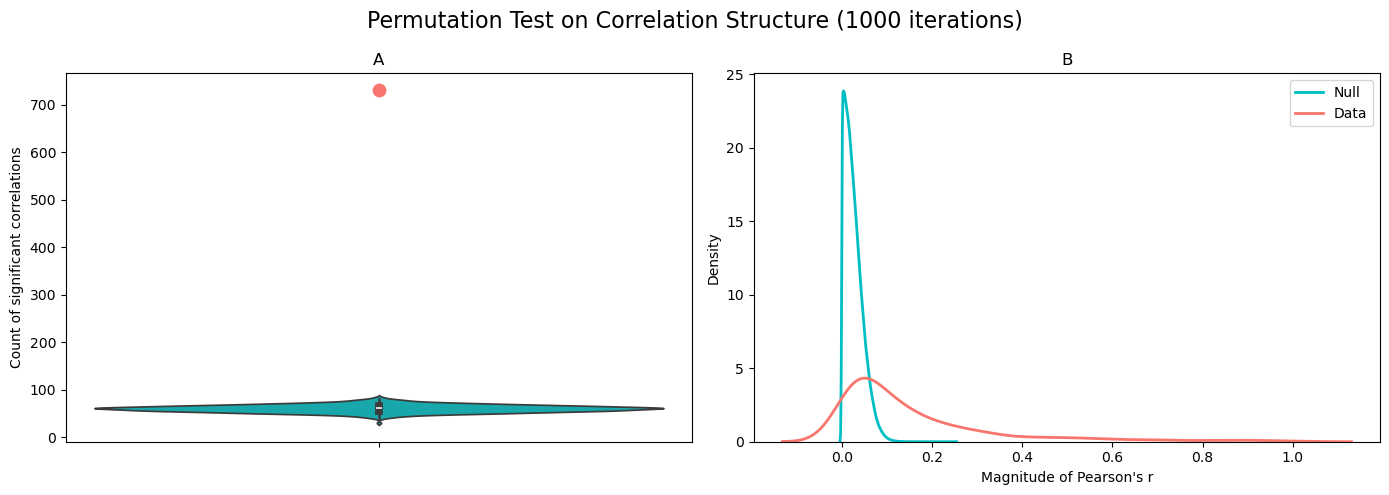

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

alpha = 0.05
obs_sig_count = np.sum(obs_pvals < alpha)
obs_abs_rs = np.abs(obs_rs)


plt.figure(figsize=(14, 5))

# Panel A: Count of significant correlations
plt.subplot(1, 2, 1)
sns.violinplot(y=null_sig_counts, color="#00BFC4")
plt.scatter([0], [obs_sig_count], color="#F8766D", s=80, zorder=5)
plt.ylabel("Count of significant correlations")
plt.title("A")

# Panel B: Magnitude of correlations
plt.subplot(1, 2, 2)
sns.kdeplot(null_rs_all, color="#00BFC4", linewidth=2, label="Null")
sns.kdeplot(obs_abs_rs, color="#F8766D", linewidth=2, label="Data")
plt.xlabel("Magnitude of Pearson's r")
plt.ylabel("Density")
plt.legend()
plt.title("B")

plt.suptitle("Permutation Test on Correlation Structure (1000 iterations)", fontsize=16)
plt.tight_layout()

# save the plot
plt.savefig(os.path.join(curfolder, "plots", "permutation_test_correlations.png"), dpi=300, bbox_inches='tight')
plt.show()


In [14]:
X_raw = df_numerical
feature_names = df_numerical.columns.to_list()

obs_corrs = []

for i in range(X_raw.shape[1]):
    for j in range(i+1, X_raw.shape[1]):
        r, p = pearsonr(X_raw.iloc[:, i], X_raw.iloc[:, j])
        obs_corrs.append({
            "feat1": feature_names[i],
            "feat2": feature_names[j],
            "r": r,
            "abs_r": abs(r),
            "p": p
        })

obs_corrs_df = pd.DataFrame(obs_corrs)

alpha = 0.05

obs_sig_count = np.sum(obs_corrs_df["p"] < alpha)

print("Correlation test results.")
print(f"Count of significant pairwise correlations in original data at alpha = {alpha}: {obs_sig_count}")
print(f"Mean significant pairwise correlations in permuted data (n = 1000) at alpha = {alpha}: {null_sig_counts.mean():.3f}")
print(f"Min = {null_sig_counts.min()}, Max = {null_sig_counts.max()}.")

top_n = 5

top_corrs = obs_corrs_df.sort_values("abs_r", ascending=False).head(top_n)

print("\nTop 5 pairwise correlations in original data:")
for _, row in top_corrs.iterrows():
    print(f"{row['feat1']}, {row['feat2']}: {row['r']:.2f}")



Correlation test results.
Count of significant pairwise correlations in original data at alpha = 0.05: 731
Mean significant pairwise correlations in permuted data (n = 1000) at alpha = 0.05: 60.881
Min = 30, Max = 85.

Top 5 pairwise correlations in original data:
gross__rhythm__band1_band_power_totalarm, gross__rhythm__band2_band_power_totalarm: -1.00
fine__handshape__handshape_size_mean, fine__variability__handshape_size_std: 1.00
fine__variability__fingertip_spread_std, fine__handshape__thumb_index_mean: 0.97
gross__rhythm__band2_centroid_totalarm, gross__rhythm__band2_entropy_totalarm: 0.96
gross__magnitude__arm_acc_peak_mean, gross__rhythm__arm_acc_mod_depth: 0.95


# PCA all froups (fine + gross)

<br>
Now, we first standardize the data and apply PCA to extract principal components. We use custom function  (adapted from [here](https://stackoverflow.com/questions/50796024/feature-variable-importance-after-a-pca-analysis)) to visualize the first two principal components. Data points are color-coded on the target variable (groupID) and red arrows represent the contributions of selected variables to the PC.

## Interactive Biplot

In [98]:
def interactive_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None, 
                            arrow_strength=None, pc_x=1, pc_y=2, show_labels=True,
                            concepts=None, highlight_concepts=None, le=None):
    ix, iy = pc_x - 1, pc_y - 1
    xs = score[:, ix]
    ys = score[:, iy]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring concepts.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # --- Discrete color mapping per group ---
    groups = np.unique(y)
    palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'
    ]
    color_map = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    traces = []

    # --- One scatter trace per group ---
    for g in groups:
        mask = y == g
        traces.append(go.Scatter(
            x=xs[mask], y=ys[mask],
            mode='markers',
            marker=dict(size=8, color=color_map[g], opacity=0.6),
            name=group_name(g),
            text=[group_name(g) + (f"<br>{concepts[i]}" if concepts is not None else "")
                  for i in np.where(mask)[0]],
            hoverinfo='text',
            showlegend=True
        ))

    # --- Highlighted concept overlays ---
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            mask = np.where(concepts == concept)[0]

            seen_groups = {}
            for idx in mask:
                group = y[idx]
                if group not in seen_groups:
                    seen_groups[group] = idx

            representative_indices = list(seen_groups.values())

            traces.append(go.Scatter(
                x=xs[representative_indices],
                y=ys[representative_indices],
                mode='markers',
                marker=dict(size=12, color='red', symbol='star',
                            line=dict(color='black', width=1)),
                name=concept,
                text=[f"{concept} — {group_name(y[i])}" for i in representative_indices],
                hoverinfo='text',
                showlegend=True
            ))

    # --- Arrows ---
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    base_scale = 10

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = base_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)

        traces.append(go.Scatter(
            x=[0, coeff[i, ix] * scale],
            y=[0, coeff[i, iy] * scale],
            mode='lines+markers+text' if show_labels else 'lines+markers',
            line=dict(color='black'),
            marker=dict(size=4),
            text=[None, var_name] if show_labels else None,
            textposition='top center',
            hovertext=var_name,
            hoverinfo='text',
            showlegend=False
        ))

    layout = go.Layout(
        title=f"Interactive PCA Biplot — PC{pc_x} vs PC{pc_y}",
        xaxis=dict(title=f'PC{pc_x}'),
        yaxis=dict(title=f'PC{pc_y}'),
        width=900, height=700,
        hovermode='closest',
    )

    go.Figure(data=traces, layout=layout).show()

In [99]:
# make concepts as list
concepts = df_clean['concept'].tolist()
# now get rid of concept col
df_clean = df_clean.drop(columns=['concept'])

print(f"concepts: {len(concepts)}, df_clean rows: {len(df_clean)}")  # sanity check

concepts: 902, df_clean rows: 902


In [100]:
# save it 

df_clean.to_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'), index=False)

In [101]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [102]:
def static_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None,
                      arrow_strength=None, pc_x=1, pc_y=2, show_labels=True,
                      concepts=None, highlight_concepts=None, le=None,
                      figsize=(12, 9), save_path=None, dpi=300):
    """
    Presentation-quality static PCA biplot with centroids.

    Parameters
    ----------
    score           : np.ndarray, shape (n_samples, n_components)
    coeff           : np.ndarray, shape (n_vars, n_components)
    labels          : list of str, variable names for arrows
    y               : np.ndarray, group labels (int or str)
    selected_vars   : list of int, indices of variables to draw arrows for
    arrow_strength  : dict {var_name: scale_factor}
    pc_x, pc_y      : int, which PCs to plot (1-indexed)
    show_labels     : bool, annotate arrow tips with variable names
    concepts        : np.ndarray, concept label per sample
    highlight_concepts : list of str, concepts to highlight with star markers
    le              : sklearn LabelEncoder for decoding group labels
    figsize         : tuple
    save_path       : str or None — if given, saves figure to this path
    dpi             : int, resolution for saved figure
    """

    ix, iy = pc_x - 1, pc_y - 1
    xs = score[:, ix]
    ys = score[:, iy]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # ── Palette ───────────────────────────────────────────────────────────────
    PALETTE = [
        "#4C72B0", "#DD8452", "#55A868", "#C44E52",
        "#8172B3", "#937860", "#DA8BC3", "#8C8C8C",
    ]
    groups = np.unique(y)
    color_map = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(groups)}

    # ── Figure setup ──────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, facecolor="#FAFAFA")
    ax.set_facecolor("#FAFAFA")

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_color("#CCCCCC")

    ax.axhline(0, color="#CCCCCC", linewidth=0.8, zorder=0)
    ax.axvline(0, color="#CCCCCC", linewidth=0.8, zorder=0)
    ax.grid(True, linestyle="--", linewidth=0.5, color="#E0E0E0", zorder=0)

    # ── Scatter per group ─────────────────────────────────────────────────────
    for g in groups:
        mask = y == g
        c = color_map[g]
        ax.scatter(
            xs[mask], ys[mask],
            color=to_rgba(c, 0.55),
            edgecolors=to_rgba(c, 0.85),
            linewidths=0.5,
            s=85,
            zorder=2,
            label=group_name(g),
        )

    # ── Centroids ─────────────────────────────────────────────────────────────
    for g in groups:
        mask = y == g
        cx, cy = xs[mask].mean(), ys[mask].mean()
        c = color_map[g]
        ax.scatter(
            cx, cy,
            color=c,
            edgecolors="white",
            linewidths=1.8,
            s=200,
            marker="X",
            zorder=5,
        )
        ax.annotate(
            group_name(g),
            xy=(cx, cy),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color=c,
            zorder=6,
        )

    # ── Highlighted concepts ──────────────────────────────────────────────────
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            idx_all = np.where(concepts == concept)[0]
            seen_groups = {}
            for idx in idx_all:
                g = y[idx]
                if g not in seen_groups:
                    seen_groups[g] = idx
            rep_indices = list(seen_groups.values())

            ax.scatter(
                xs[rep_indices], ys[rep_indices],
                color="crimson",
                edgecolors="black",
                linewidths=0.8,
                s=180,
                marker="*",
                zorder=7,
                label=concept,
            )

    # ── Arrows ────────────────────────────────────────────────────────────────
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    base_scale = 10

    arrowprops = dict(
        arrowstyle="-|>",
        color="#2B2B2B",
        lw=1.5,
        mutation_scale=12,
    )

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = base_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)
        ex, ey = coeff[i, ix] * scale, coeff[i, iy] * scale

        ax.annotate(
            "",
            xy=(ex, ey),
            xytext=(0, 0),
            arrowprops=arrowprops,
            zorder=4,
        )

        if show_labels:
            # Nudge label slightly beyond arrow tip
            offset = 0.05 * np.array([ex, ey])
            ax.text(
                ex + offset[0], ey + offset[1],
                var_name,
                fontsize=8.5,
                ha="center",
                va="center",
                color="#2B2B2B",
                fontweight="semibold",
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.75,
                ),
                zorder=5,
            )

    # ── Labels & title ────────────────────────────────────────────────────────
    ax.set_xlabel(f"PC{pc_x}", fontsize=13, labelpad=8, color="#333333")
    ax.set_ylabel(f"PC{pc_y}", fontsize=13, labelpad=8, color="#333333")
    ax.set_title(
        f"PCA Biplot — PC{pc_x} vs PC{pc_y}",
        fontsize=15,
        fontweight="bold",
        color="#1A1A1A",
        pad=14,
    )
    ax.tick_params(colors="#555555", labelsize=9)

    # ── Legend (groups only, centroids explained in title note) ───────────────
    group_handles = [
        mpatches.Patch(color=color_map[g], label=group_name(g), alpha=0.8)
        for g in groups
    ]
    centroid_handle = plt.Line2D(
        [0], [0],
        marker="X",
        color="w",
        markerfacecolor="#555555",
        markeredgecolor="white",
        markersize=9,
        label="Centroid",
    )
    handles = group_handles + [centroid_handle]

    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            handles.append(
                plt.Line2D(
                    [0], [0],
                    marker="*",
                    color="w",
                    markerfacecolor="crimson",
                    markeredgecolor="black",
                    markersize=11,
                    label=concept,
                )
            )

    ax.legend(
        handles=handles,
        loc="best",
        fontsize=9,
        framealpha=0.9,
        edgecolor="#CCCCCC",
        fancybox=False,
    )

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Figure saved to: {save_path}")

    plt.show()
    return fig, ax

## PC1-PC2

In [103]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features

df_clean['groupID'] = df_clean['groupID'].astype('category')
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GS = StandardScaler()
Xz_GS = scaler_GS.fit_transform(X)    

# PCA transformation
pca_GS = PCA()
x_new_GS = pca_GS.fit_transform(Xz_GS)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GS = pca_GS.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # PC1 and PC2 (the PCs you plot below)
    component = loadings_GS[:, i]      # column i = all variables' loadings ON PC i
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       concepts=concepts,
                       le=le,
                       highlight_concepts=None  # or None for no highlighting
                    
                    )

## PC2-PC3

In [104]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, 
                       pc_y=3,
                       concepts = concepts,
                       le=le,
                       show_labels=False)

## PC3-PC4

In [105]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, 
                       pc_y=4,
                       le=le,
                       show_labels=False)

## P4-P5

In [106]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=4, 
                       pc_y=5,
                       le=le,
                       show_labels=False)

In [107]:
print("Unique levels in target column:", np.unique(df_clean.iloc[:, -1]))

Unique levels in target column: ['Gesture' 'Learner_1' 'Learner_2' 'Sign']


## Bootstrap PCA

In [108]:
def bootstrap_pca(Xz, n_boot=1000):

    rng = np.random.default_rng(42)

    boot_loadings = []
    boot_eigs = []

    n = Xz.shape[0]

    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        Xb = Xz[idx]
        pca_b = PCA().fit(Xb)
        boot_loadings.append(pca_b.components_.T)
        boot_eigs.append(pca_b.explained_variance_)

    boot_loadings = np.array(boot_loadings)
    boot_eigs = np.array(boot_eigs)

    # total variance per bootstrap PCA (needed to convert eigvals -> variance explained)
    boot_total_var = np.sum(boot_eigs, axis=1, keepdims=True)

    # bootstrap variance explained per PC
    boot_var_explained = boot_eigs / boot_total_var

    # mean and SD of bootstrap variance explained
    boot_var_mean = boot_var_explained.mean(axis=0)
    boot_var_sd = boot_var_explained.std(axis=0)

    # # sanity check shapes
    # print(boot_var_mean.shape, boot_var_sd.shape)

    loading_ci_low = np.percentile(boot_loadings, 5, axis=0)
    loading_ci_high = np.percentile(boot_loadings, 95, axis=0)

    eig_ci_low = np.percentile(boot_eigs, 2.5, axis=0)
    eig_ci_high = np.percentile(boot_eigs, 97.5, axis=0)

    # bind all results into a dictionary for easy access
    results = {
        "boot_loadings": boot_loadings,
        "boot_eigs": boot_eigs,
        "boot_var_mean": boot_var_mean,
        "boot_var_sd": boot_var_sd,
        "loading_ci_low": loading_ci_low,
        "loading_ci_high": loading_ci_high,
        "eig_ci_low": eig_ci_low,
        "eig_ci_high": eig_ci_high
    }

    return results

bootstrap_results_GS = bootstrap_pca(Xz_GS)

## Null PCA (permutation test)

In [109]:
def permutation_pca(Xz, n_boot=1000):

    rng = np.random.default_rng(42)

    null_loadings = []
    null_eigs = []

    for _ in range(n_boot):
        #
        Xnull = np.apply_along_axis(rng.permutation, 0, Xz)
        pca_n = PCA().fit(Xnull)
        null_loadings.append(pca_n.components_.T)
        null_eigs.append(pca_n.explained_variance_)

    null_loadings = np.array(null_loadings)
    null_eigs = np.array(null_eigs)

    null_loading_thresh = np.percentile(np.abs(null_loadings), 95, axis=0)
    null_eig_thresh = np.percentile(null_eigs, 95, axis=0)

    results = {
        "null_loadings": null_loadings,
        "null_eigs": null_eigs,
        "null_loading_thresh": null_loading_thresh,
        "null_eig_thresh": null_eig_thresh
    }

    return results

permutation_results_GS = permutation_pca(Xz_GS)


## Significance mask

In [110]:
# determine significant PCs
var_explained_GS = pca_GS.explained_variance_ratio_
null_var_thresh_GS = permutation_results_GS["null_eig_thresh"] / np.sum(pca_GS.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GS = var_explained_GS > null_var_thresh_GS

In [111]:
sig_pc_effect_GS = var_explained_GS > 0.05  # 5% cut-off
sig_pc_GS = sig_pc_null_GS & sig_pc_effect_GS

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GS, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GS[i-1]:.3f}")

Significant PCs:
PC1: significant = True, var explained = 0.159
PC2: significant = True, var explained = 0.129
PC3: significant = True, var explained = 0.116
PC4: significant = True, var explained = 0.085
PC5: significant = True, var explained = 0.056
PC6: significant = False, var explained = 0.042
PC7: significant = False, var explained = 0.039
PC8: significant = False, var explained = 0.034
PC9: significant = False, var explained = 0.031
PC10: significant = False, var explained = 0.028
PC11: significant = False, var explained = 0.026
PC12: significant = False, var explained = 0.022
PC13: significant = False, var explained = 0.020
PC14: significant = False, var explained = 0.019
PC15: significant = False, var explained = 0.018
PC16: significant = False, var explained = 0.016
PC17: significant = False, var explained = 0.015
PC18: significant = False, var explained = 0.015
PC19: significant = False, var explained = 0.014
PC20: significant = False, var explained = 0.013
PC21: significant

In [112]:
import os
sig_idx = np.where(sig_pc_GS)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GS[:, sig_idx], columns=pc_cols)

meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_all.csv'), index=False)

In [113]:
def plot_pca_variance(var_explained,
                             boot_ci_low,
                             boot_ci_high,
                             null_thresh,
                             max_pcs=20):
    """
    var_explained: array of variance explained ratios (e.g. pca.explained_variance_ratio_)
    boot_ci_low: bootstrap CI lower bound (variance ratio)
    boot_ci_high: bootstrap CI upper bound (variance ratio)
    null_thresh: null 95% threshold (variance ratio)
    """

    pcs = np.arange(1, len(var_explained) + 1)

    # optionally truncate to first N PCs (keeps plot readable)
    pcs = pcs[:max_pcs]
    var_explained = var_explained[:max_pcs]
    boot_ci_low = boot_ci_low[:max_pcs]
    boot_ci_high = boot_ci_high[:max_pcs]

    plt.figure(figsize=(10, 6))

    # CI bars
    plt.vlines(
        pcs,
        boot_ci_low * 100,
        boot_ci_high * 100,
        colors='black',
        linewidth=1,
        alpha=0.7
    )

    # observed variance points
    plt.scatter(
        pcs,
        var_explained * 100,
        color='red',
        s=40,
        zorder=3,
        label="Sampling"
    )

    # null threshold line
    plt.plot(
    pcs,
    null_thresh[:len(pcs)] * 100,
    linestyle='--',
    color='teal',
    linewidth=2,
    label="Null"
)


    plt.xlabel("Principal Component")
    plt.ylabel("Variance Explained (%)")
    plt.title("Variance Explained by Principal Components")

    plt.xticks(pcs, [f"PC{i}" for i in pcs], rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.show()


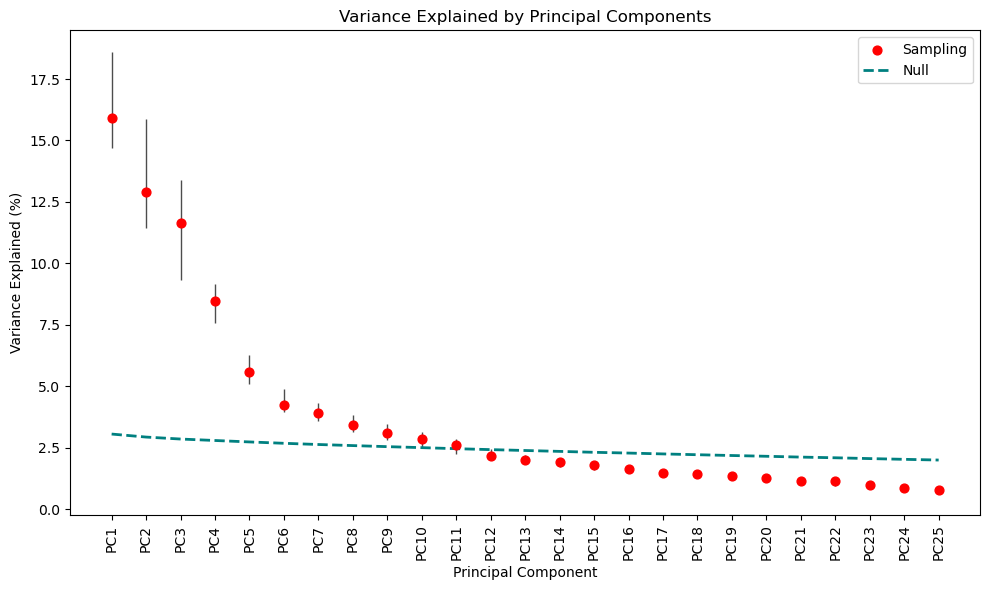

<Figure size 640x480 with 0 Axes>

In [114]:
boot_var_ci_low_GS = bootstrap_results_GS["eig_ci_low"] / np.sum(pca_GS.explained_variance_)
boot_var_ci_high_GS = bootstrap_results_GS["eig_ci_high"] / np.sum(pca_GS.explained_variance_)
null_var_thresh_GS = permutation_results_GS["null_eig_thresh"] / np.sum(pca_GS.explained_variance_)

plot_pca_variance(
    var_explained=pca_GS.explained_variance_ratio_,
    boot_ci_low=boot_var_ci_low_GS,
    boot_ci_high=boot_var_ci_high_GS,
    null_thresh=null_var_thresh_GS,
    max_pcs=25   # adjust for readability
)

# save this plot
plt.savefig(os.path.join(curfolder, "Plots", "GS_all_pca_variance_explained.png"), dpi=300, bbox_inches='tight')

In [115]:
n_pcs = len(pca_GS.explained_variance_ratio_)

pc_names = [f"PC{i+1}" for i in range(n_pcs)]

df_variance_GS = pd.DataFrame({
    "PC": pc_names,
    "variance_explained": pca_GS.explained_variance_ratio_,
    "low_confint_var": boot_var_ci_low_GS,
    "high_confint_var": boot_var_ci_high_GS,
    "mean_confint_var": bootstrap_results_GS["boot_var_mean"],
    "sd_confint_var": bootstrap_results_GS["boot_var_sd"],
    "null_thresh": null_var_thresh_GS
})

# significance: observed variance > null threshold
df_variance_GS["sig_PC"] = df_variance_GS["variance_explained"] > df_variance_GS["null_thresh"]

# filter significant PCs
df_sig_pcs_GS = df_variance_GS.loc[df_variance_GS["sig_PC"], [
    "PC",
    "variance_explained",
    "low_confint_var",
    "high_confint_var",
    "mean_confint_var",
    "sd_confint_var"
]]

# convert to %
df_sig_pcs_GS.loc[:, df_sig_pcs_GS.columns != "PC"] *= 100

df_sig_pcs_GS


,PC,variance_explained,low_confint_var,high_confint_var,mean_confint_var,sd_confint_var
0,PC1,15.922173,14.712516,18.583640,16.422610,0.763225
1,PC2,12.919852,11.431286,15.870526,13.321261,0.745711
2,PC3,11.638930,9.323691,13.383355,11.212492,0.819327
3,PC4,8.471022,7.592897,9.149086,8.443551,0.391451
4,PC5,5.585572,5.112946,6.273968,5.677655,0.315413
5,PC6,4.248646,3.952794,4.893537,4.418877,0.237557
6,PC7,3.931457,3.592021,4.315105,3.953173,0.188328
7,PC8,3.412786,3.160326,3.852081,3.496549,0.162601
8,PC9,3.120435,2.815959,3.472021,3.150027,0.131401
9,PC10,2.846319,2.544747,3.156102,2.853841,0.141281


## Significant variables

Which variables are significant?

In [116]:
def identify_sigvar(pca, bootstrap_results, permutation_results, df_clean):

    # compute index loadings
    loadings = pca.components_.T
    eigs = pca.explained_variance_

    # index loadings for original PCA
    index_loadings = (loadings ** 2) * (eigs ** 2)

    # compute bootrap index loadings
    boot_index_loadings = (bootstrap_results["boot_loadings"] ** 2) * (bootstrap_results["boot_eigs"][:, None, :] ** 2)

    # 90% CI (matches loadings_confint = 0.9)
    low_q = 5
    high_q = 95

    boot_index_ci_low = np.percentile(boot_index_loadings, low_q, axis=0)
    boot_index_ci_high = np.percentile(boot_index_loadings, high_q, axis=0)

    # compute null index loadings
    null_index_loadings = (permutation_results["null_loadings"] ** 2) * (permutation_results["null_eigs"][:, None, :] ** 2)

    null_index_ci_low = np.percentile(null_index_loadings, low_q, axis=0)
    null_index_ci_high = np.percentile(null_index_loadings, high_q, axis=0)

    sig_vars = []

    for pc in range(loadings.shape[1]):
        for feat in range(loadings.shape[0]):
            sig_vars.append({
                "PC": pc + 1,
                "feature": df_clean.columns[feat],
                "loading": loadings[feat, pc],
                "index_loading": index_loadings[feat, pc],
                "low_confint": boot_index_ci_low[feat, pc],
                "high_confint": boot_index_ci_high[feat, pc],
                "low_null": null_index_ci_low[feat, pc],
                "high_null": null_index_ci_high[feat, pc],
                "sig_loading": index_loadings[feat, pc] > null_index_ci_high[feat, pc]
            })

    df_sig_vars = pd.DataFrame(sig_vars)

    return df_sig_vars

In [117]:
df_sig_vars_GS = identify_sigvar(pca_GS, bootstrap_results_GS, permutation_results_GS, df_clean)
df_sig_vars_GS[df_sig_vars_GS["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
9,1,gross__magnitude__arm_acc_peak_mean,0.329348,6.889968,3.638227,8.267916,0.000218,0.150083,True
8,1,gross__variability__arm_acc_Gstd,0.325436,6.727264,3.500835,8.231119,0.000219,0.165372,True
6,1,gross__rhythm__arm_speed_mod_depth,0.320376,6.519724,3.507360,7.685385,0.000193,0.154838,True
1,1,gross__variability__arm_speed_Gstd,0.316742,6.372636,2.825733,8.339462,0.000171,0.156666,True
2,1,gross__magnitude__arm_speed_peak_mean,0.314342,6.276438,2.829837,8.008140,0.000181,0.153073,True
...,...,...,...,...,...,...,...,...,...
733,15,gross__proxdist__proximalization_index,0.652331,0.352074,0.000920,0.341690,0.000119,0.097169,True
731,15,gross__coordination__arm_coupling,-0.379412,0.119102,0.000481,0.190289,0.000103,0.107444,True
826,17,gross__rhythm__band3_dom_freq_totalarm,0.553739,0.169446,0.000521,0.217195,0.000143,0.094717,True
897,18,fine__smoothness__flexion_jerk,0.476503,0.120176,0.000241,0.153102,0.000102,0.086729,True


In [118]:
for pc in df_sig_pcs_GS["PC"]:
    pc_no = int(pc.replace("PC", ""))
    print(f"\nPC{pc_no} significant contributors:")
    display(
        df_sig_vars_GS[(df_sig_vars_GS["PC"] == pc_no) & (df_sig_vars_GS["sig_loading"])]
        .sort_values("index_loading", ascending=False)
        .head(10)
    )


PC1 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
9,1,gross__magnitude__arm_acc_peak_mean,0.329348,6.889968,3.638227,8.267916,0.000218,0.150083,True
8,1,gross__variability__arm_acc_Gstd,0.325436,6.727264,3.500835,8.231119,0.000219,0.165372,True
6,1,gross__rhythm__arm_speed_mod_depth,0.320376,6.519724,3.507360,7.685385,0.000193,0.154838,True
1,1,gross__variability__arm_speed_Gstd,0.316742,6.372636,2.825733,8.339462,0.000171,0.156666,True
2,1,gross__magnitude__arm_speed_peak_mean,0.314342,6.276438,2.829837,8.008140,0.000181,0.153073,True
13,1,gross__rhythm__arm_acc_mod_depth,0.312617,6.207747,3.317479,7.248145,0.000230,0.145651,True
7,1,gross__magnitude__arm_acc_Gmean,0.216295,2.971666,1.029278,4.652178,0.000229,0.156724,True
15,1,gross__rhythm__arm_speed_sampen,-0.168029,1.793395,0.598526,3.273990,0.000258,0.151128,True
5,1,gross__rhythm__arm_speed_peak_rate,-0.162739,1.682252,0.333162,3.707943,0.000194,0.148622,True
12,1,gross__rhythm__arm_acc_peak_rate,-0.157386,1.573411,0.203569,3.727515,0.000234,0.163365,True



PC2 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
61,2,gross__rhythm__arm_acc_peak_n,0.298172,3.718369,0.362927,4.653360,0.000129,0.149451,True
64,2,gross__magnitude__arm_speed_integral,0.289910,3.515165,0.034297,5.279511,0.000172,0.141822,True
54,2,gross__rhythm__arm_speed_peak_n,0.281267,3.308695,0.335559,4.440337,0.000212,0.138532,True
74,2,gross__rhythm__band2_band_power_totalarm,0.255680,2.734083,0.088953,4.714649,0.000131,0.157589,True
70,2,gross__rhythm__band1_band_power_totalarm,-0.252781,2.672436,0.077660,4.671682,0.000141,0.156278,True
69,2,gross__rhythm__band1_centroid_totalarm,0.216267,1.956134,0.112292,2.802351,0.000138,0.140295,True
50,2,gross__magnitude__arm_speed_Gmean,0.213293,1.902704,0.008669,3.750281,0.000196,0.138737,True
62,2,gross__rhythm__arm_acc_peak_rate,0.210401,1.851452,0.063576,3.256403,0.000211,0.176587,True
80,2,gross__magnitude__bbmv_arms_total,0.192794,1.554551,0.009273,2.761029,0.000290,0.148558,True
71,2,gross__rhythm__band1_entropy_totalarm,0.185876,1.444993,0.071440,2.104940,0.000274,0.148921,True



PC3 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
134,3,fine__handshape__fingertip_spread_mean,0.305808,3.174157,0.014301,3.918648,0.000131,0.144582,True
136,3,fine__handshape__thumb_index_mean,0.299772,3.050094,0.008991,3.912933,0.000159,0.141687,True
144,3,fine__variability__handshape_variability,0.288384,2.822743,0.082811,3.585148,0.000135,0.150277,True
135,3,fine__variability__fingertip_spread_std,0.286706,2.789986,0.006525,3.690858,0.000167,0.146969,True
145,3,fine__magnitude__flexion_speed_mean,0.285247,2.761674,0.390500,3.342576,0.000173,0.148493,True
137,3,fine__variability__thumb_index_std,0.281482,2.689241,0.049335,3.534253,0.000184,0.145584,True
138,3,fine__handshape__mcp_tip_mean,0.270811,2.489210,0.043582,3.116890,0.000125,0.160543,True
146,3,fine__variability__flexion_speed_std,0.237956,1.921864,0.104925,2.502923,0.000149,0.136336,True
139,3,fine__variability__mcp_tip_std,0.232292,1.831471,0.031148,2.427099,0.000149,0.140219,True
140,3,fine__handshape__thumb_opposition_mean,0.195053,1.291322,0.002913,1.996830,0.000173,0.151944,True


... (12 outputs left out)


PC10 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
472,10,gross__rhythm__band2_dom_freq_totalarm,0.408778,0.339192,0.000562,0.534005,0.000101,0.124806,True
453,10,gross__variability__arm_speed_peak_std,-0.376324,0.287472,0.002033,0.433478,0.000151,0.109882,True
474,10,gross__rhythm__band2_band_power_totalarm,0.291643,0.172653,0.000351,0.260760,0.000143,0.114695,True
470,10,gross__rhythm__band1_band_power_totalarm,-0.281699,0.161080,0.000371,0.251760,0.000182,0.111991,True
460,10,gross__variability__arm_acc_peak_std,-0.281314,0.160640,0.001192,0.278606,0.000198,0.115779,True
498,10,fine__coordination__finger_independence,0.273718,0.152082,0.001159,0.393176,0.000159,0.111081,True



PC11 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
532,11,gross__coordination__arm_asymmetry,0.435593,0.329104,0.002415,0.478359,0.000144,0.122058,True
533,11,gross__proxdist__proximalization_index,0.398989,0.276116,0.003621,0.442997,0.000091,0.105498,True
548,11,fine__coordination__finger_independence,-0.300050,0.156156,0.000998,0.352749,0.000092,0.115959,True
522,11,gross__rhythm__band2_dom_freq_totalarm,0.289728,0.145597,0.000859,0.347151,0.000121,0.100605,True
530,11,gross__magnitude__bbmv_arms_total,-0.282883,0.138798,0.002896,0.165235,0.000113,0.121519,True


In [119]:
def plot_index_loadings(df_pc, pc_name="PC3"):
    plt.figure(figsize=(12, 6))

    x = np.arange(len(df_pc))

    # bootstrap CI
    plt.vlines(
        x,
        df_pc["boot_low"],
        df_pc["boot_high"],
        color="red",
        alpha=0.6,
        linewidth=2,
        label="Bootstrap CI"
    )

    # null threshold (mean across variables like R plot)
    # null threshold, per variable (matches nzilbb.vowels)
    plt.plot(
        x, df_pc["null_thresh"].values,
        color="turquoise", linestyle="--", linewidth=1.5,
        marker="_", markersize=8, label="Null threshold"
    )

    # observed index loadings
    for i, row in df_pc.iterrows():
        marker = "+" if row["loading_sign"] > 0 else "_"
        plt.plot(
            x[df_pc.index.get_loc(i)],
            row["obs_index"],
            marker=marker,
            color="black",
            markersize=10
        )

    plt.xticks(x, df_pc["variable"], rotation=90)
    plt.ylabel("Index Loading")
    plt.title(f"Index Loadings for {pc_name}\nBootstrap CIs + Permutation Null")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [120]:
def index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                      feature_names, loadings_confint=0.9,
                      filter_boots=False, quantile_threshold=0.25):
    """Index loadings for one PC, with optional filter_boots stabilisation
    (matches nzilbb.vowels::plot_loadings). Returns (tidy_df, n_kept_iterations)."""
    half = (1 - loadings_confint) / 2
    lowq, highq = 100 * half, 100 * (1 - half)          # 5 / 95 for confint=0.9

    # observed index loadings for this PC
    obs_l = pca.components_.T[:, pc_idx]
    obs_e = pca.explained_variance_[pc_idx]
    obs_index = (obs_l ** 2) * (obs_e ** 2)

    # bootstrap index loadings: (n_boot, n_feat)
    bl = bootstrap_results["boot_loadings"][:, :, pc_idx]
    be = bootstrap_results["boot_eigs"][:, pc_idx][:, None]
    boot_index = (bl ** 2) * (be ** 2)

    kept = np.ones(boot_index.shape[0], dtype=bool)
    if filter_boots:
        winner = int(np.argmax(np.median(boot_index, axis=0)))       # highest-median variable
        thresh = np.percentile(boot_index[:, winner], 100 * quantile_threshold)
        kept = boot_index[:, winner] >= thresh                       # top 3/4 of its distribution
    bi = boot_index[kept]

    # null threshold (permuted iterations are NOT filtered, matching R)
    nl = permutation_results["null_loadings"][:, :, pc_idx]
    ne = permutation_results["null_eigs"][:, pc_idx][:, None]
    null_index = (nl ** 2) * (ne ** 2)

    df = pd.DataFrame({
        "variable": feature_names,
        "obs_index": obs_index,
        "boot_low":  np.percentile(bi, lowq,  axis=0),
        "boot_high": np.percentile(bi, highq, axis=0),
        "null_thresh": np.percentile(null_index, highq, axis=0),
        "loading_sign": np.sign(obs_l),
    })
    df["sig_loading"] = df["obs_index"] > df["null_thresh"]
    return df.sort_values("obs_index").reset_index(drop=True), int(kept.sum())


def plot_loadings_compare(pca, bootstrap_results, permutation_results, pc_idx,
                          feature_names, pc_name=None, loadings_confint=0.9,
                          quantile_threshold=0.25):
    """Side-by-side unfiltered vs filtered index-loading plot for one PC."""
    pc_name = pc_name or f"PC{pc_idx + 1}"
    df_uf, n_uf = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                    feature_names, loadings_confint, filter_boots=False)
    df_fl, n_fl = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                    feature_names, loadings_confint, filter_boots=True,
                                    quantile_threshold=quantile_threshold)
    order = df_uf["variable"].tolist()                     # keep both panels on same x-order
    df_fl = df_fl.set_index("variable").loc[order].reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
    for ax, df, title, n in [(axes[0], df_uf, "Unfiltered bootstrap", n_uf),
                             (axes[1], df_fl, "Filtered bootstrap",   n_fl)]:
        x = np.arange(len(df))
        ax.vlines(x, df["boot_low"], df["boot_high"], color="red", alpha=0.6, lw=2,
                  label="Bootstrap CI")
        ax.hlines(df["null_thresh"].mean(), -1, len(df), color="turquoise",
                  ls="--", lw=2, label="Null threshold")
        for i, r in df.iterrows():
            ax.plot(i, r["obs_index"], marker=("+" if r["loading_sign"] > 0 else "_"),
                    color="black", ms=10)
        ax.set_xticks(x); ax.set_xticklabels(df["variable"], rotation=90)
        ax.set_title(f"{title} ({n} iters)"); ax.set_ylabel("Index loading"); ax.legend()
    fig.suptitle(f"Index loadings for {pc_name}: unfiltered vs filtered", fontsize=14)
    fig.tight_layout()
    plt.show()
    return df_uf, df_fl

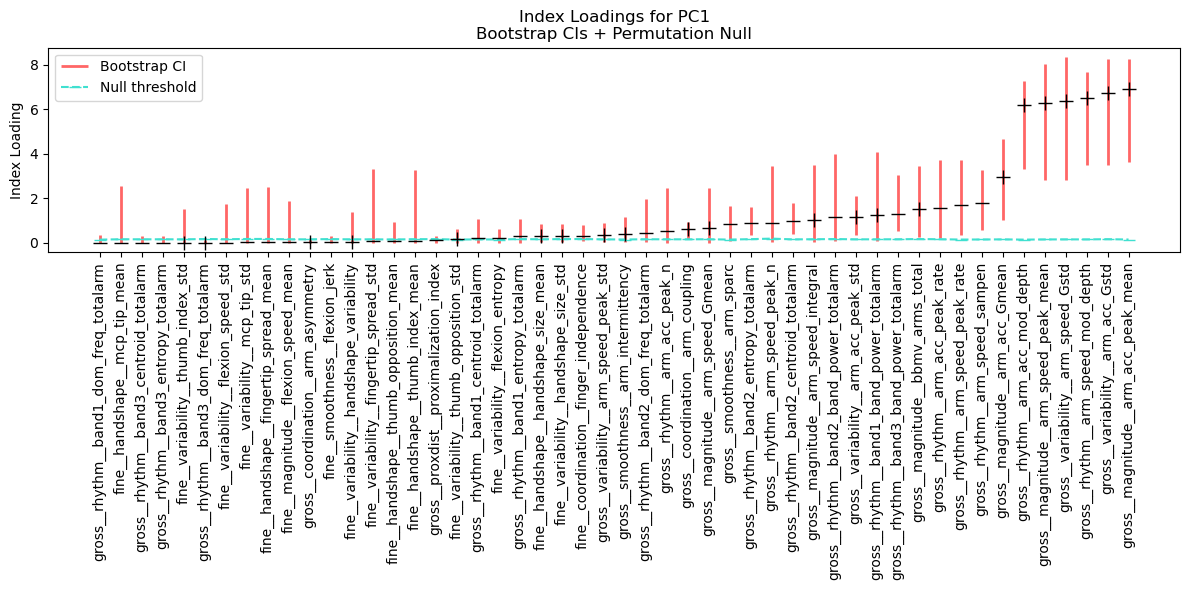

In [121]:
pc_idx = 0  # PC1

# observed
obs_loadings_GS = pca_GS.components_[pc_idx]
obs_eig_GS = pca_GS.explained_variance_[pc_idx]
obs_index_GS = (obs_loadings_GS**2) * (obs_eig_GS**2)

# bootstrap index loadings
boot_index_GS = (bootstrap_results_GS["boot_loadings"][:, :, pc_idx]**2) * (bootstrap_results_GS["boot_eigs"][:, pc_idx][:, None]**2)

boot_low_GS = np.percentile(boot_index_GS, 5, axis=0)
boot_high_GS = np.percentile(boot_index_GS, 95, axis=0)

# null index loadings
null_index_GS = (permutation_results_GS["null_loadings"][:, :, pc_idx]**2) * (permutation_results_GS["null_eigs"][:, pc_idx][:, None]**2)
null_thresh_GS = np.percentile(null_index_GS, 95, axis=0)

df_pc_GS = pd.DataFrame({
    "variable": df_clean.columns[:-1],
    "obs_index": obs_index_GS,
    "boot_low": boot_low_GS,
    "boot_high": boot_high_GS,
    "null_thresh": null_thresh_GS,
    "loading_sign": np.sign(obs_loadings_GS )
})

df_pc_GS = df_pc_GS.sort_values("obs_index")

plot_index_loadings(df_pc_GS, pc_name="PC1")



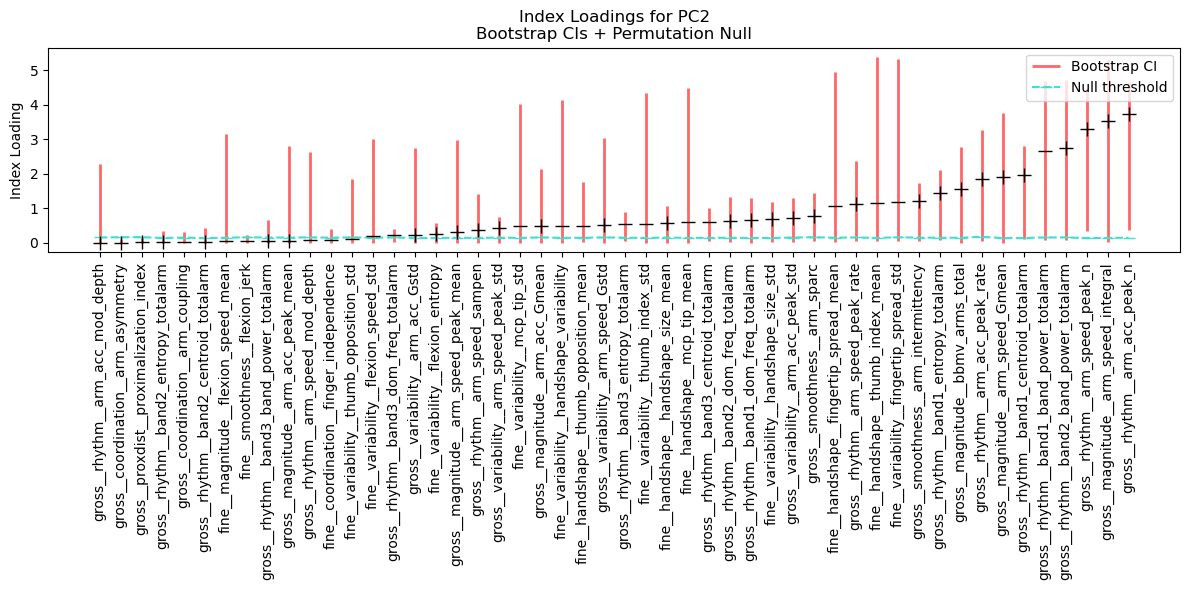

In [122]:
pc_idx = 1  # PC2

# observed
obs_loadings_GS = pca_GS.components_[pc_idx]
obs_eig_GS = pca_GS.explained_variance_[pc_idx]
obs_index_GS = (obs_loadings_GS**2) * (obs_eig_GS**2)

# bootstrap index loadings
boot_index_GS = (bootstrap_results_GS["boot_loadings"][:, :, pc_idx]**2) * (bootstrap_results_GS["boot_eigs"][:, pc_idx][:, None]**2)

boot_low_GS = np.percentile(boot_index_GS, 5, axis=0)
boot_high_GS = np.percentile(boot_index_GS, 95, axis=0)

# null index loadings
null_index_GS = (permutation_results_GS["null_loadings"][:, :, pc_idx]**2) * (permutation_results_GS["null_eigs"][:, pc_idx][:, None]**2)
null_thresh_GS = np.percentile(null_index_GS, 95, axis=0)

df_pc_GS = pd.DataFrame({
    "variable": df_clean.columns[:-1],
    "obs_index": obs_index_GS,
    "boot_low": boot_low_GS,
    "boot_high": boot_high_GS,
    "null_thresh": null_thresh_GS,
    "loading_sign": np.sign(obs_loadings_GS )
})

df_pc_GS = df_pc_GS.sort_values("obs_index")

plot_index_loadings(df_pc_GS, pc_name="PC2")

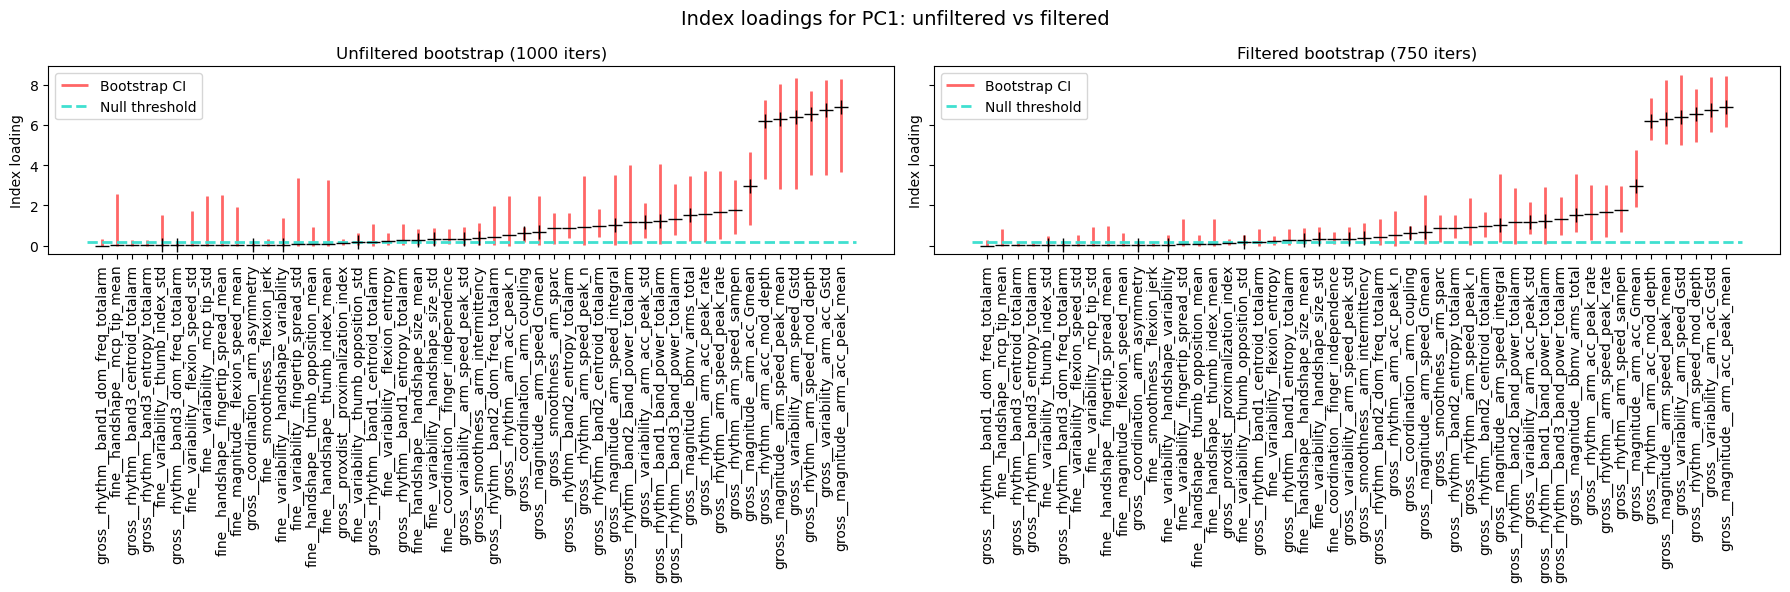

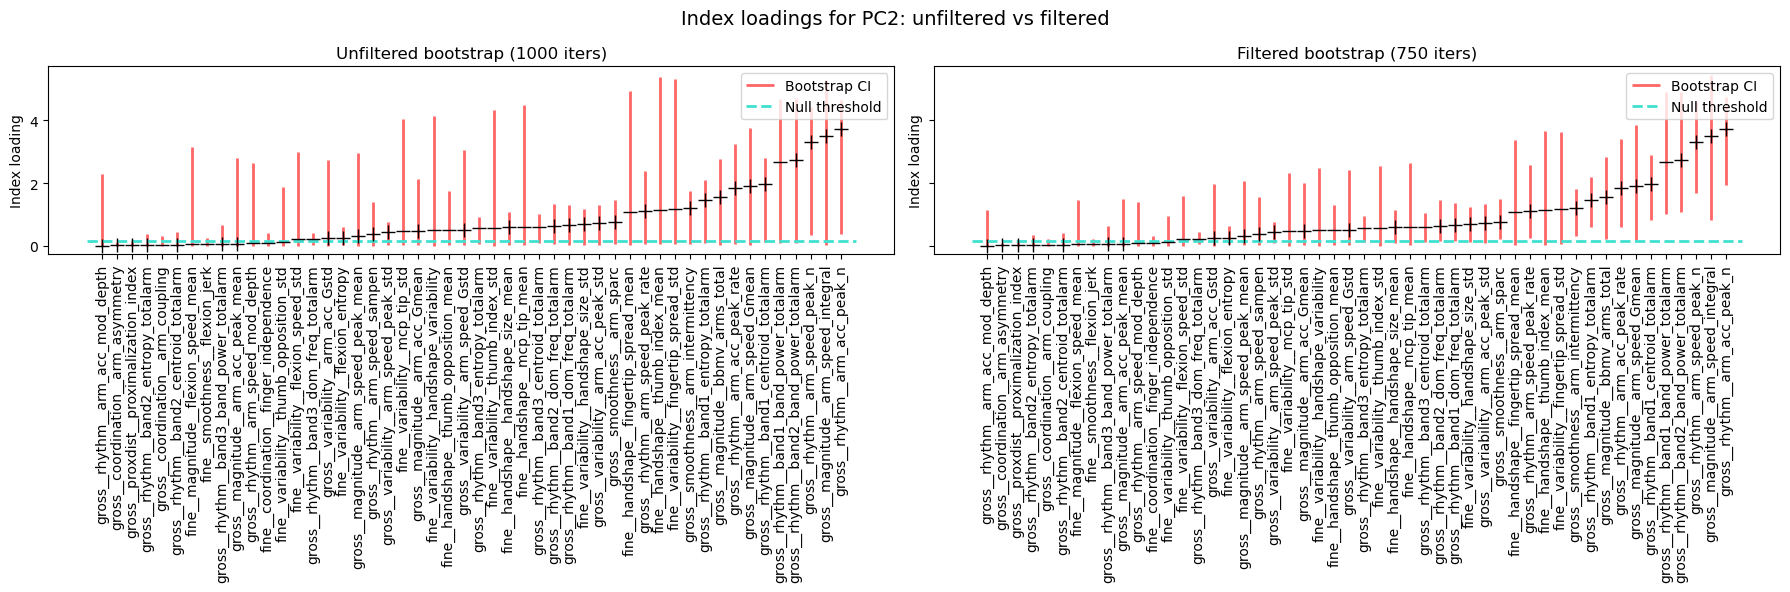

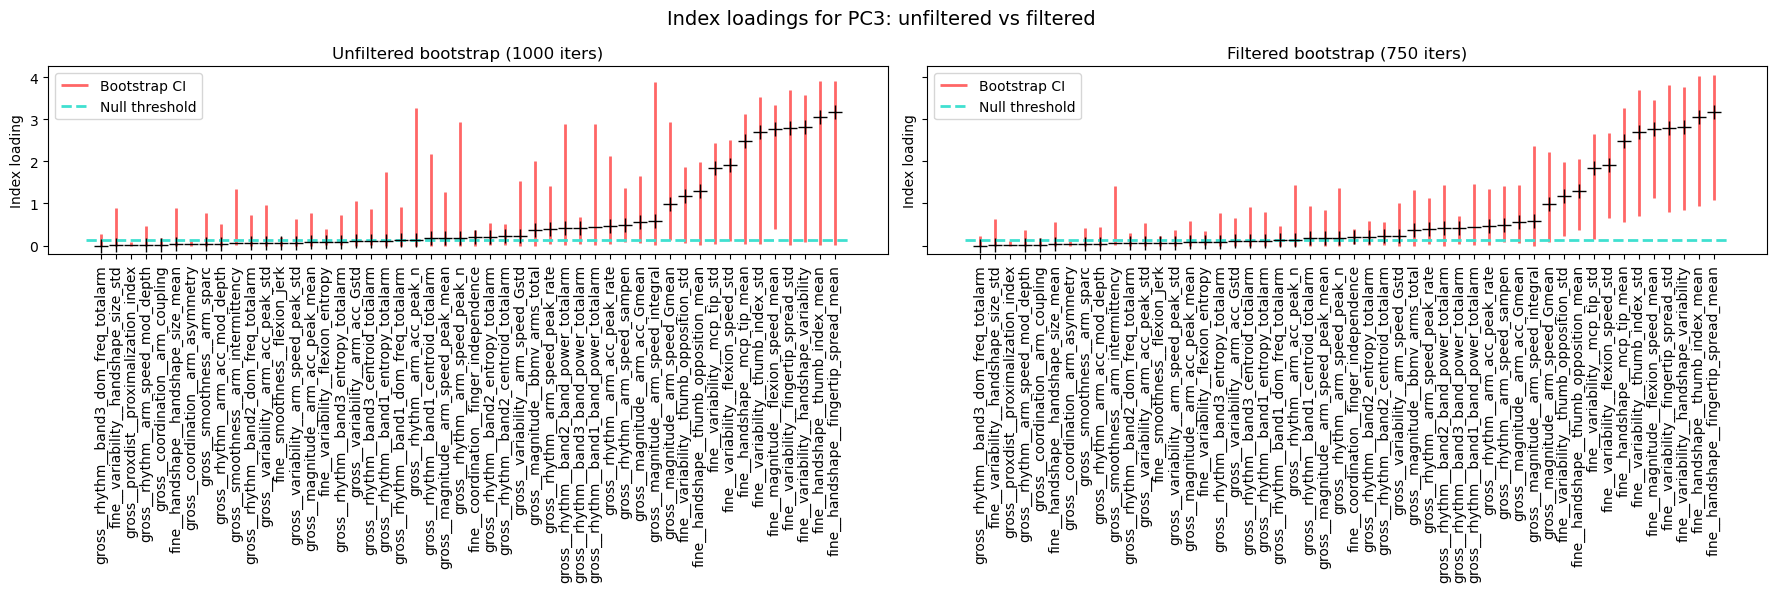

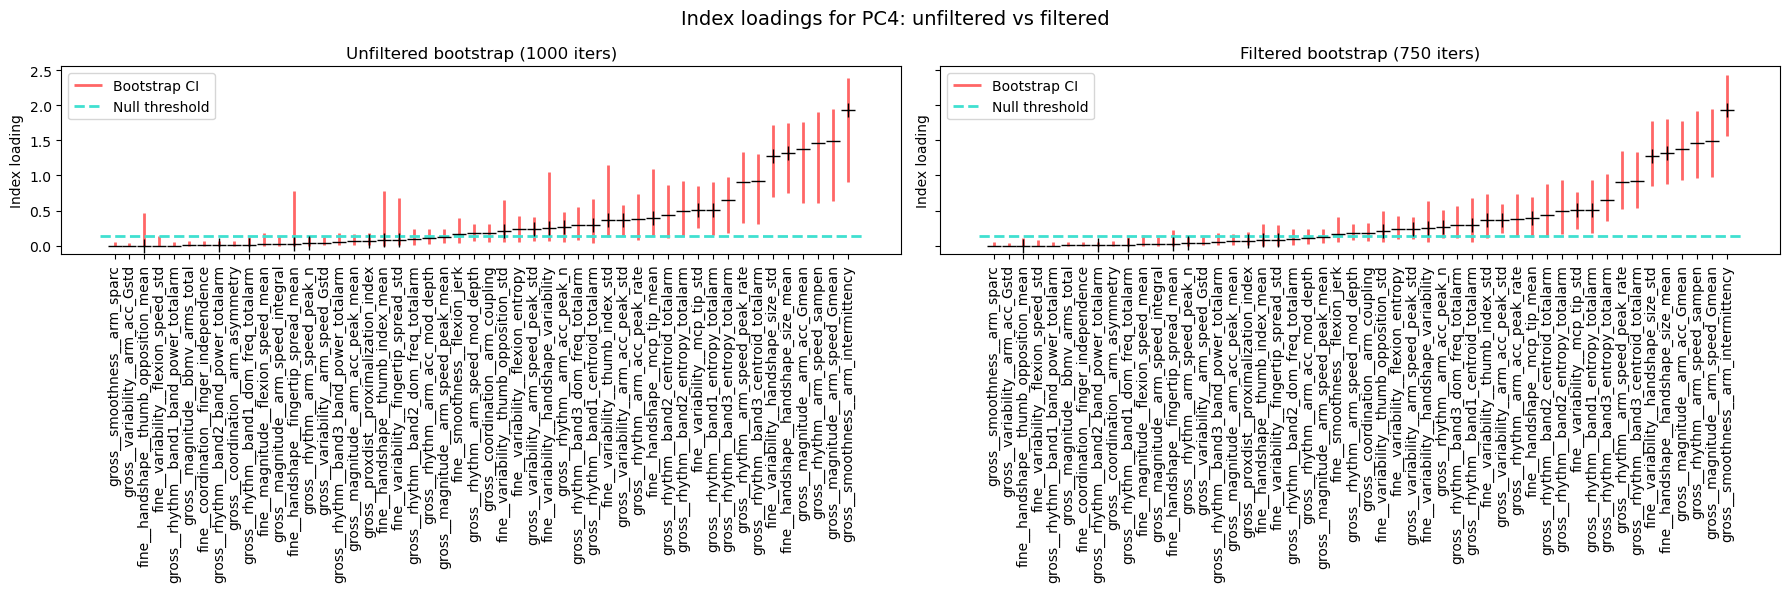

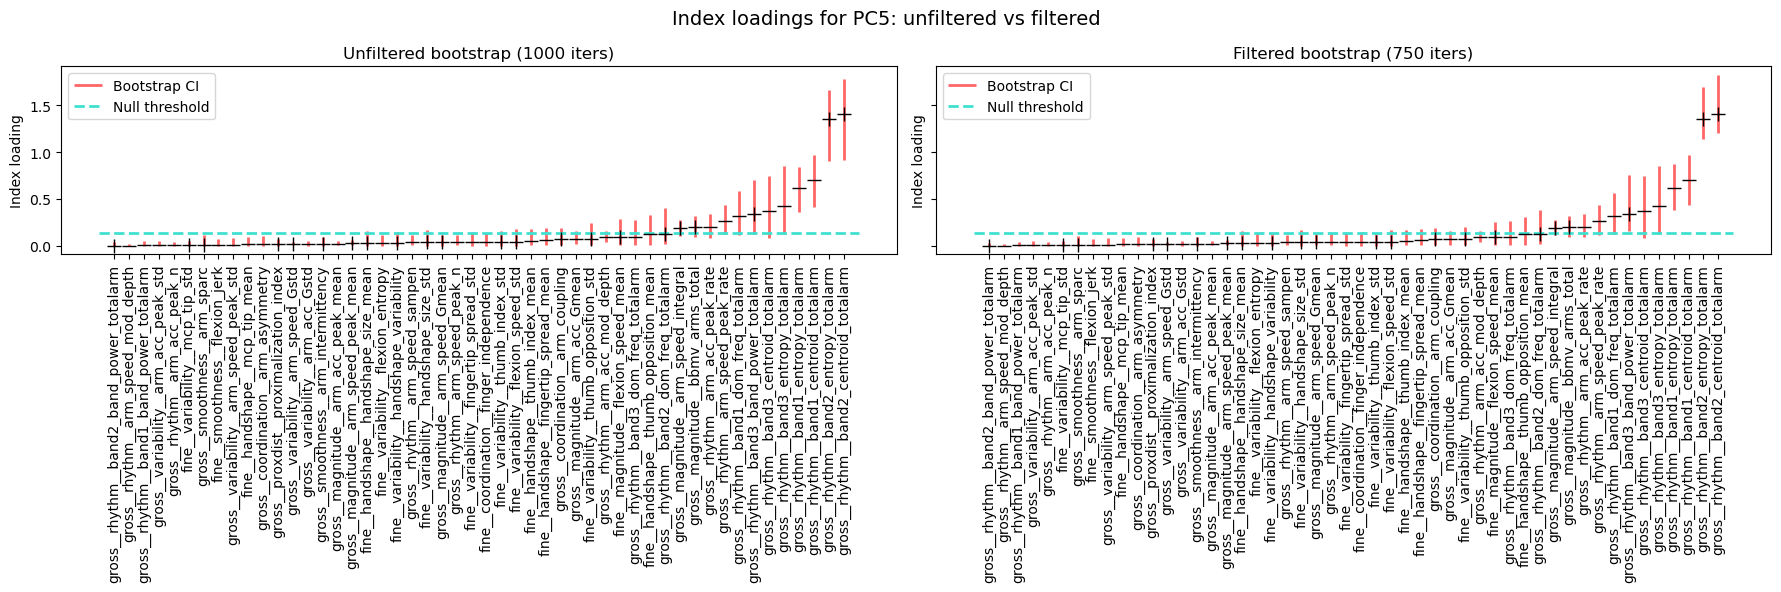

In [123]:
# Compare original vs filtered bootstrap for EVERY significant PC (GS / all groups)
for pc in np.where(sig_pc_GS)[0]:
    plot_loadings_compare(pca_GS, bootstrap_results_GS, permutation_results_GS,
                          pc_idx=int(pc), feature_names=df_clean.columns[:-1],
                          pc_name=f"PC{pc+1}")


In [124]:
def identify_sigvar_filtered(pca, bootstrap_results, permutation_results, feature_names,
                             loadings_confint=0.9, quantile_threshold=0.25, n_pcs=None):
    n_pcs = n_pcs or pca.components_.shape[0]
    out = []
    for pc in range(n_pcs):
        df, n_kept = index_loadings_pc(pca, bootstrap_results, permutation_results, pc,
                                       feature_names, loadings_confint,
                                       filter_boots=True, quantile_threshold=quantile_threshold)
        out.append(df.assign(PC=pc + 1, kept_iterations=n_kept))
    return pd.concat(out, ignore_index=True)


# Compare which variables are "significant" before vs after filtering
df_sig_vars_GS_filt = identify_sigvar_filtered(
    pca_GS, bootstrap_results_GS, permutation_results_GS,
    feature_names=list(df_clean.columns[:-1]), n_pcs=10)

uf = df_sig_vars_GS.rename(columns={"low_confint": "boot_low", "high_confint": "boot_high"})
merged = (uf[["PC", "feature", "sig_loading"]]
          .merge(df_sig_vars_GS_filt[["PC", "variable", "sig_loading", "boot_low", "boot_high"]],
                 left_on=["PC", "feature"], right_on=["PC", "variable"],
                 suffixes=("_unfilt", "_filt")))
changed = merged[merged["sig_loading_unfilt"] != merged["sig_loading_filt"]]
print("Variables whose significance status changes after filtering:")
changed.sort_values(["PC", "feature"])

Variables whose significance status changes after filtering:


,PC,feature,sig_loading_unfilt,variable,sig_loading_filt,boot_low,boot_high


50% cumulative contribution

In [125]:
def top_until_50pct(index_loadings_pc, feature_names):
    total = index_loadings_pc.sum()
    df = pd.DataFrame({
        "feature": feature_names,
        "index_loading": index_loadings_pc
    }).sort_values("index_loading", ascending=False)
    
    df["cum_frac"] = df["index_loading"].cumsum() / total
    return df[df["cum_frac"] <= 0.5]

# Example for PC1
index_loadings_GS = (pca_GS.components_.T ** 2) * (pca_GS.explained_variance_ ** 2)
top_pc1 = top_until_50pct(index_loadings_GS[:, 0], df_clean.columns[:-1])
top_pc1


,feature,index_loading,cum_frac
9,gross__magnitude__arm_acc_peak_mean,6.889968,0.108470
8,gross__variability__arm_acc_Gstd,6.727264,0.214378
6,gross__rhythm__arm_speed_mod_depth,6.519724,0.317019
1,gross__variability__arm_speed_Gstd,6.372636,0.417345


## Plot only significant vars

### Biplot PC1-PC2

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_2_biplot.png


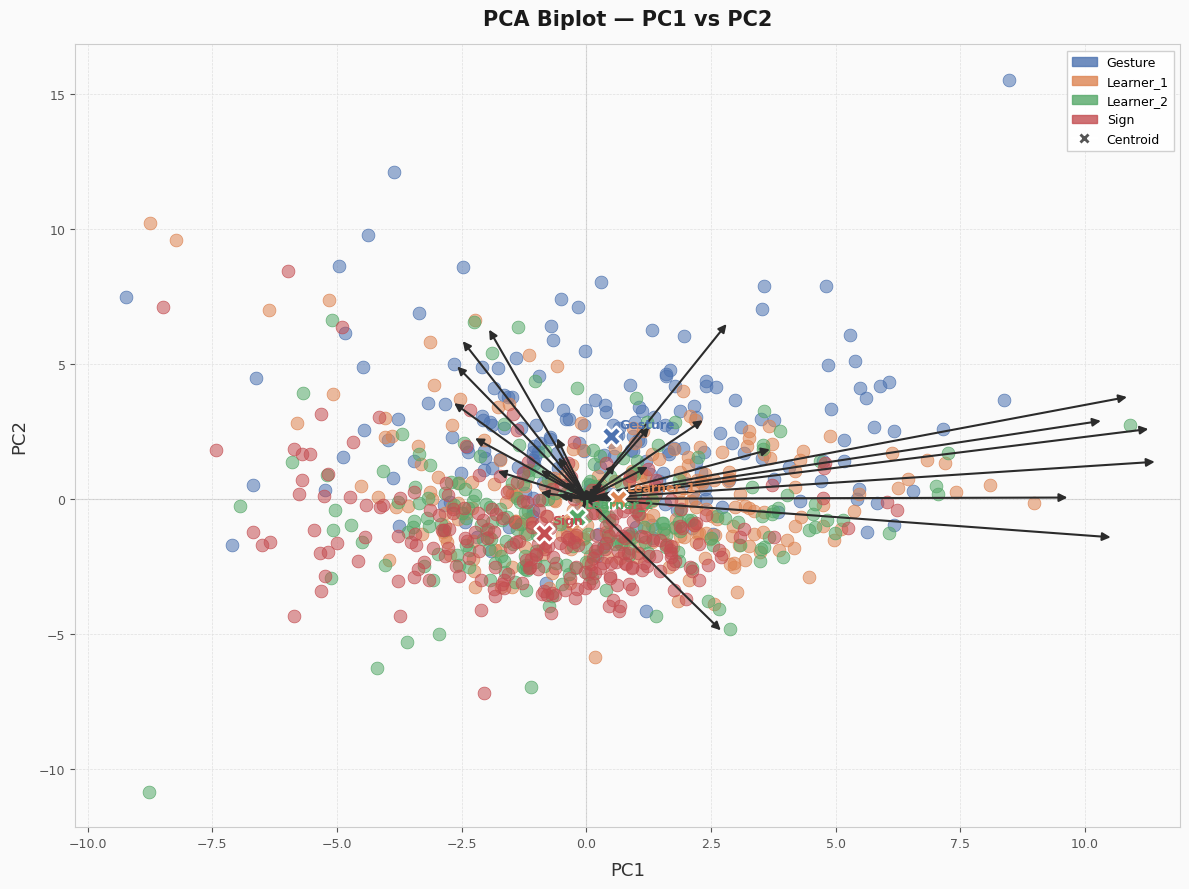

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC2'}, xlabel='PC1', ylabel='PC2'>)

In [126]:
pcs_to_plot = [1, 2]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin([1,2])]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=1, pc_y=2,
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=1, pc_y=2,
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_2_biplot.png")
)

### Biplot PC2-PC3

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC2_3_biplot.png


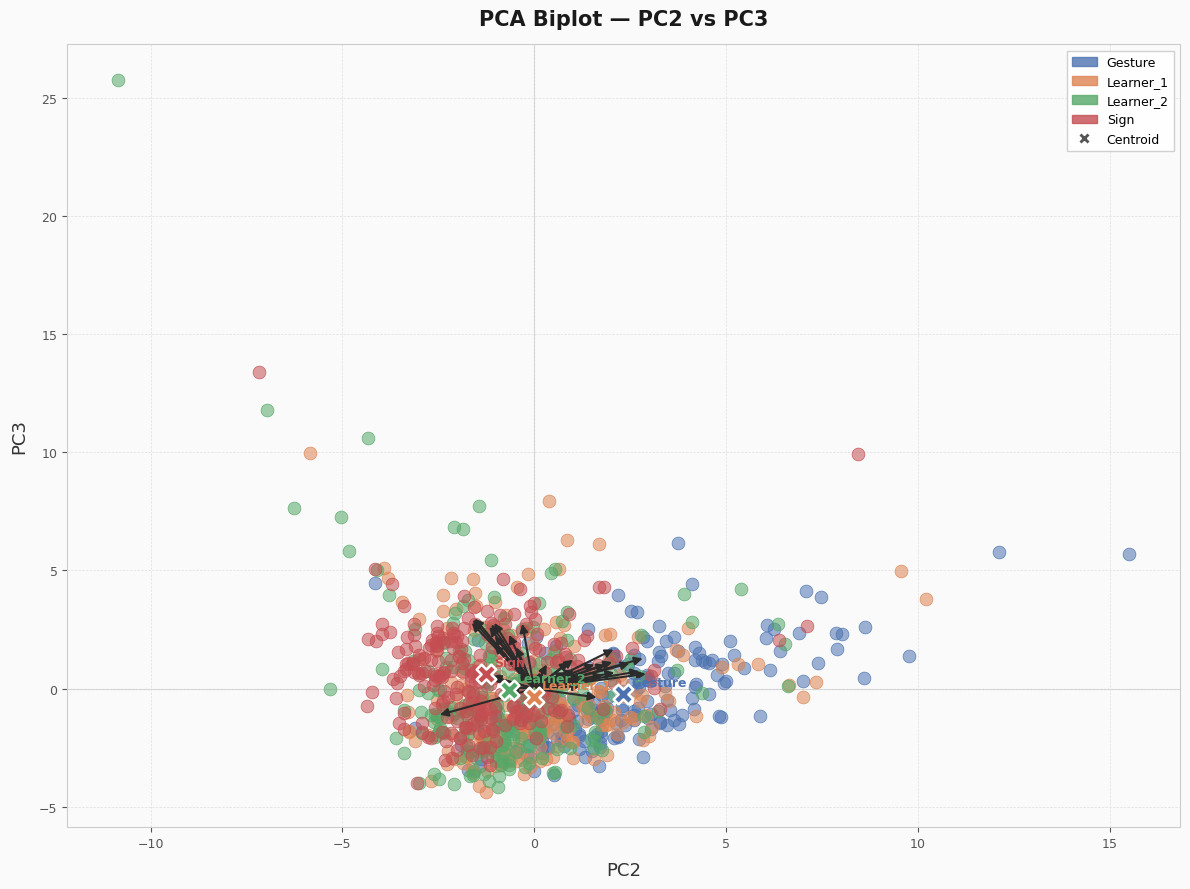

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC2 vs PC3'}, xlabel='PC2', ylabel='PC3'>)

In [127]:
pcs_to_plot = [2, 3]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin([pcs_to_plot])]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC2_3_biplot.png")
)


### Biplot PC1-PC3

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_3_biplot.png


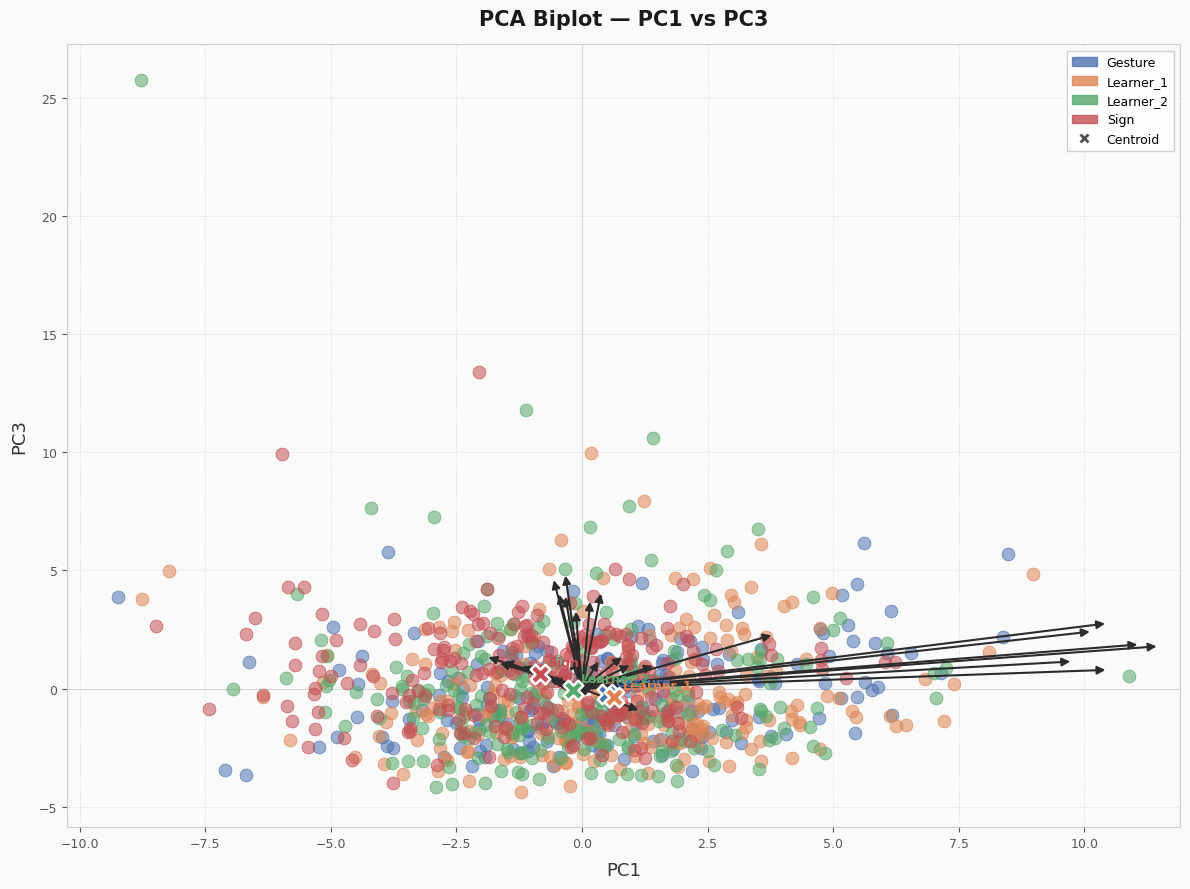

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC3'}, xlabel='PC1', ylabel='PC3'>)

In [128]:
pcs_to_plot = [1, 3]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_3_biplot.png")
)

### Biplot PC1-PC4

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_4_biplot.png


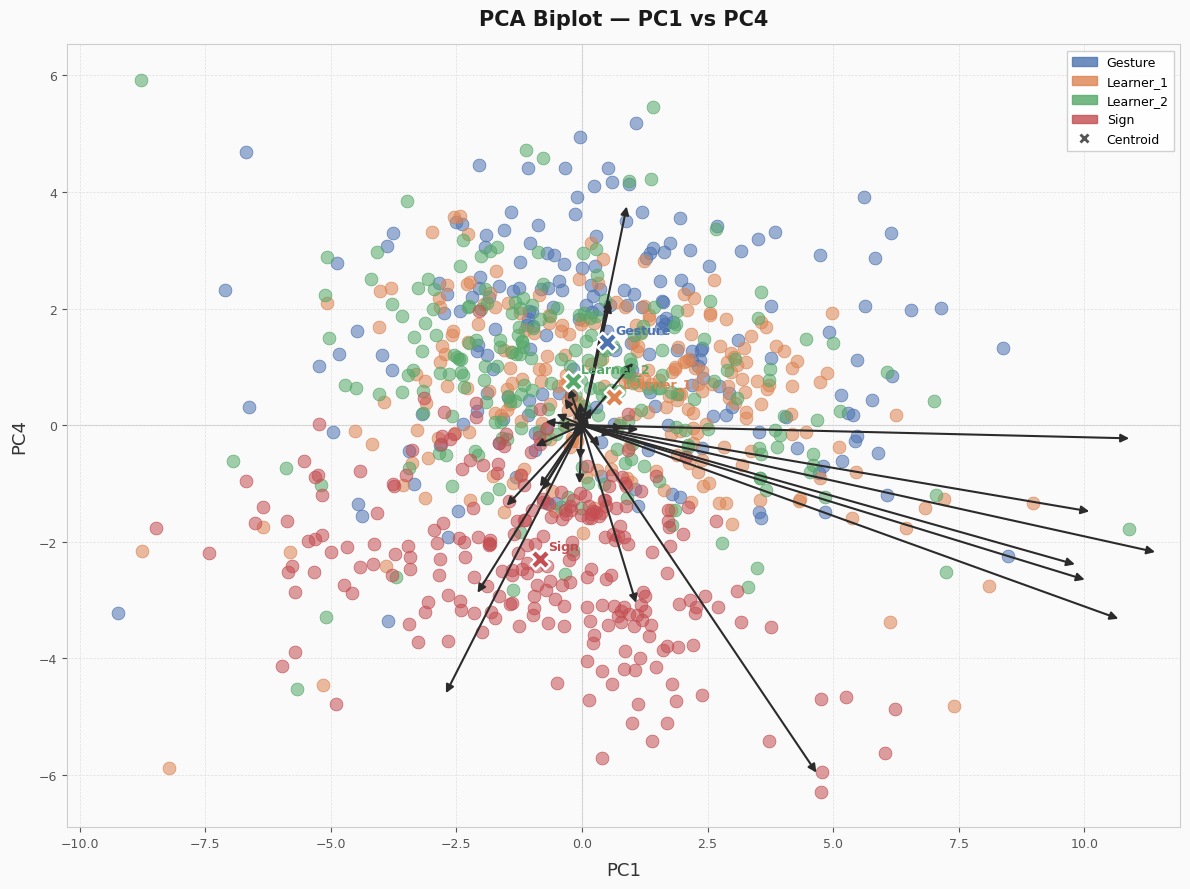

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC4'}, xlabel='PC1', ylabel='PC4'>)

In [129]:
pcs_to_plot = [1, 4]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_4_biplot.png")
)

### Biplot PC1-PC5

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC1_5_biplot.png


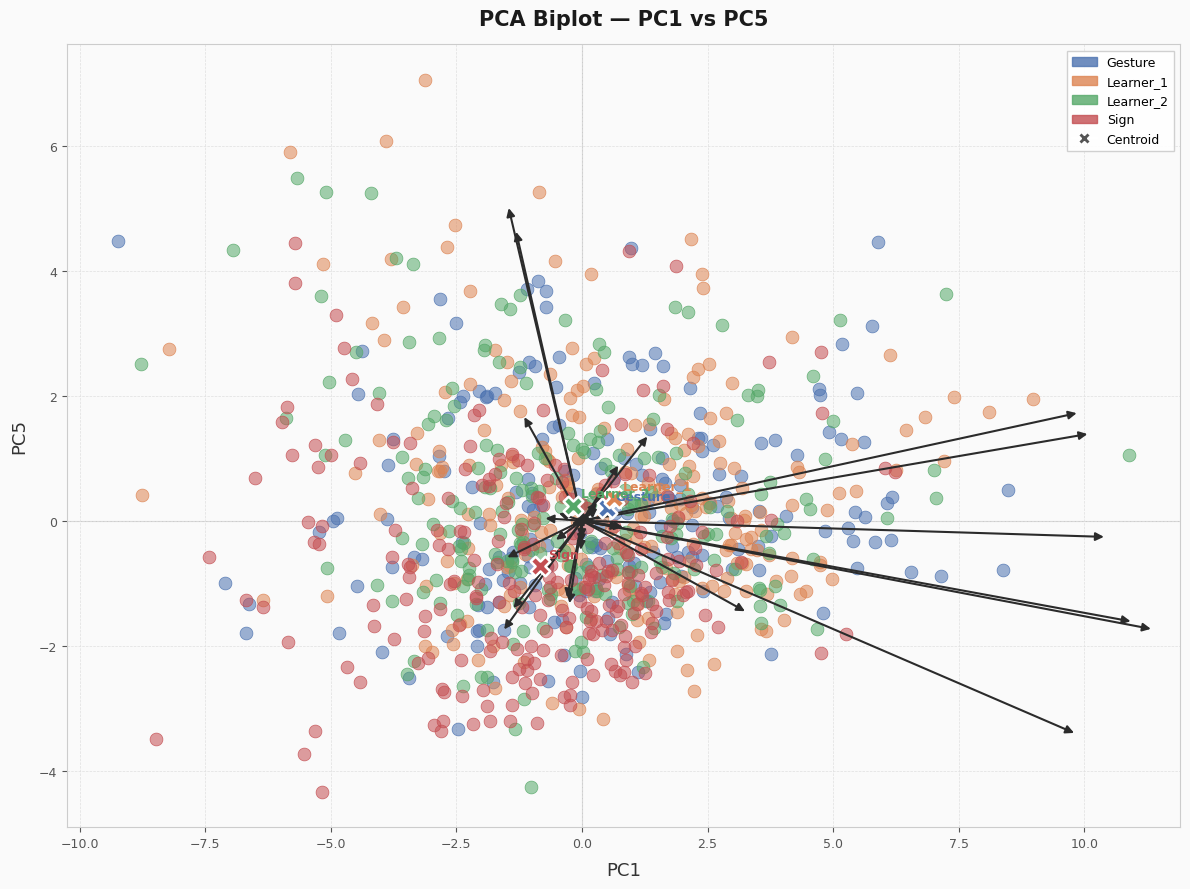

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC5'}, xlabel='PC1', ylabel='PC5'>)

In [130]:
pcs_to_plot = [1, 5]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC1_5_biplot.png")
)


### Biplot PC4-PC5 

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC4_5_biplot.png


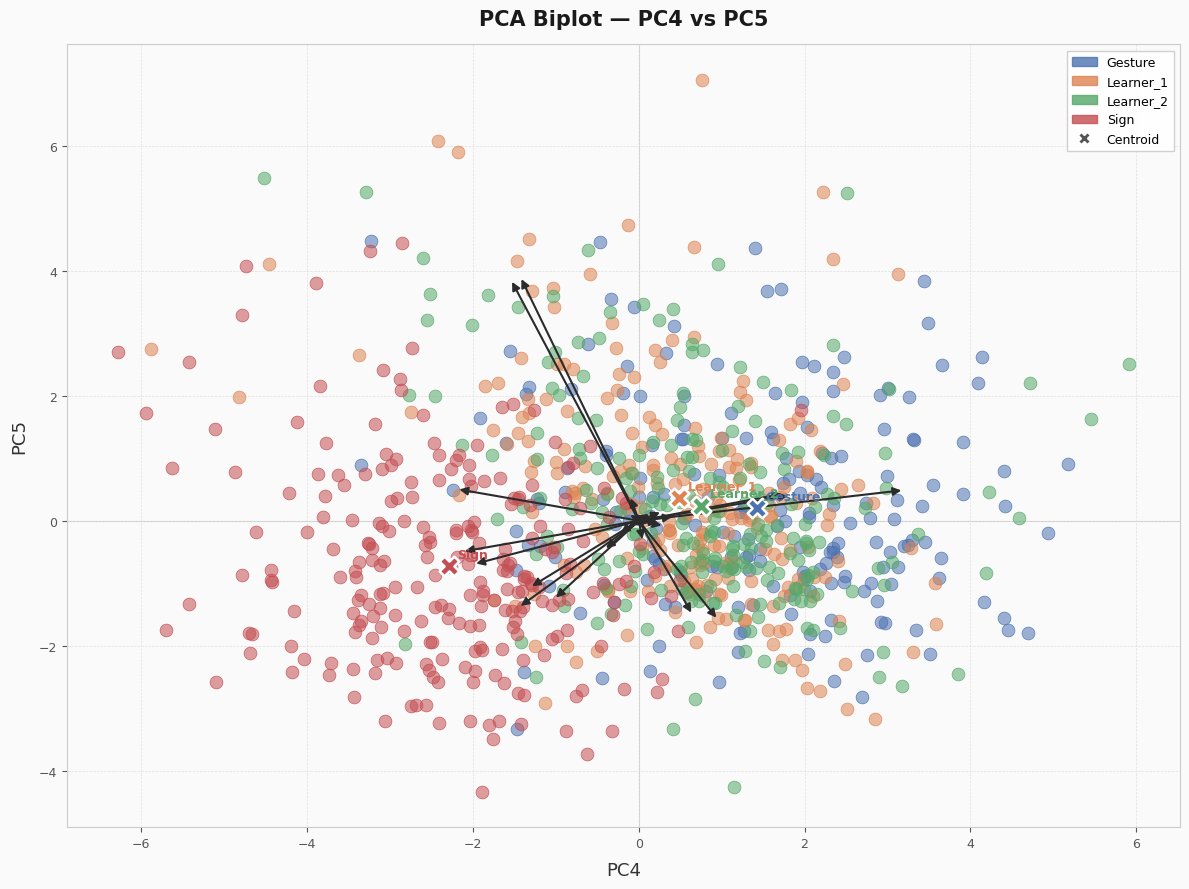

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC4 vs PC5'}, xlabel='PC4', ylabel='PC5'>)

In [131]:
pcs_to_plot = [4, 5]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC4_5_biplot.png")
)


### 3D plot

In [132]:
def interactive_PCA_biplot_3D(score, coeff, labels=None, y=None, selected_vars=None,
                               arrow_strength=None, pc_x=1, pc_y=2, pc_z=3,
                               show_labels=True, concepts=None,
                               highlight_concepts=None, le=None):
    ix, iy, iz = pc_x - 1, pc_y - 1, pc_z - 1
    xs, ys, zs = score[:, ix], score[:, iy], score[:, iz]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring concepts.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # --- Discrete color mapping per group ---
    groups = np.unique(y)
    palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'
    ]
    color_map = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    traces = []

    # --- One scatter trace per group ---
    for g in groups:
        mask = y == g
        traces.append(go.Scatter3d(
            x=xs[mask], y=ys[mask], z=zs[mask],
            mode='markers',
            marker=dict(size=5, color=color_map[g], opacity=0.7),
            name=group_name(g),
            text=[group_name(g) + (f"<br>{concepts[i]}" if concepts is not None else "")
                  for i in np.where(mask)[0]],
            hoverinfo='text',
            showlegend=True
        ))

    # --- Highlighted concept overlays ---
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            mask = np.where(concepts == concept)[0]

            seen_groups = {}
            for idx in mask:
                group = y[idx]
                if group not in seen_groups:
                    seen_groups[group] = idx

            representative_indices = list(seen_groups.values())

            traces.append(go.Scatter3d(
                x=xs[representative_indices],
                y=ys[representative_indices],
                z=zs[representative_indices],
                mode='markers',
                marker=dict(size=10, color='red', symbol='diamond',
                            line=dict(color='black', width=1)),
                name=concept,
                text=[f"{concept} — {group_name(y[i])}" for i in representative_indices],
                hoverinfo='text',
                showlegend=True
            ))

    # Arrows
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    arrow_scale = 10

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = arrow_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)

        # Arrow line
        traces.append(go.Scatter3d(
            x=[0, coeff[i, ix] * scale],
            y=[0, coeff[i, iy] * scale],
            z=[0, coeff[i, iz] * scale],
            mode='lines+markers+text' if show_labels else 'lines+markers',
            line=dict(color='black', width=3),
            marker=dict(size=3, color='black'),
            text=[None, var_name] if show_labels else None,
            textposition='top center',
            hovertext=var_name,
            hoverinfo='text',
            showlegend=False
        ))

    layout = go.Layout(
        title=f"Interactive 3D PCA Biplot — PC{pc_x} vs PC{pc_y} vs PC{pc_z}",
        scene=dict(
            xaxis_title=f"PC{pc_x}",
            yaxis_title=f"PC{pc_y}",
            zaxis_title=f"PC{pc_z}",
        ),
        width=900, height=700,
    )

    go.Figure(data=traces, layout=layout).show()

In [133]:
pcs_to_plot = [2, 3, 4]

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

# Map feature names to column indices
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

interactive_PCA_biplot_3D(
    score=x_new_GS,
    coeff=loadings_GS,
    labels=feature_names,
    y=y,
    selected_vars=selected_vars,
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1], pc_z=pcs_to_plot[2],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

## Save features

In [134]:
def select_features_for_pc(pca, bootstrap_results, permutation_results, feature_names,
                           pc_idx, loadings_confint=0.9, quantile_threshold=0.25,
                           verbose=True):
    """Which variables stay in a PC for modelling, accounting for filter_boots.
    keep = significant (obs > null) AND stable after filtering (filtered boot_low > null)."""
    fn = list(feature_names)
    df_uf, _   = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                   fn, loadings_confint, filter_boots=False)
    df_fl, n_k = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                   fn, loadings_confint, filter_boots=True,
                                   quantile_threshold=quantile_threshold)
    # anchor = the variable the filter selects on (highest median bootstrap index loading)
    bl = bootstrap_results["boot_loadings"][:, :, pc_idx]
    be = bootstrap_results["boot_eigs"][:, pc_idx][:, None]
    boot_index = (bl ** 2) * (be ** 2)
    winner = fn[int(np.argmax(np.median(boot_index, axis=0)))]

    tbl = (df_uf.rename(columns={"boot_low": "boot_low_unfilt", "boot_high": "boot_high_unfilt"})
           .merge(df_fl.rename(columns={"boot_low": "boot_low_filt",
                                        "boot_high": "boot_high_filt"})
                        [["variable", "boot_low_filt", "boot_high_filt"]], on="variable"))
    tbl["sig_obs"]       = tbl["obs_index"]       > tbl["null_thresh"]   # exclusion rule
    tbl["stable_unfilt"] = tbl["boot_low_unfilt"] > tbl["null_thresh"]
    tbl["stable_filt"]   = tbl["boot_low_filt"]   > tbl["null_thresh"]   # survives stabilisation
    tbl["is_anchor"]     = tbl["variable"] == winner
    tbl["keep"]          = tbl["sig_obs"] & tbl["stable_filt"]
    tbl = tbl.sort_values("obs_index", ascending=False).reset_index(drop=True)
    tbl["share"]        = tbl["obs_index"] / tbl["obs_index"].sum()
    # cumulative share of this PC's total index loading (over ALL features), largest first
    tbl["cum_frac"]     = tbl["obs_index"].cumsum() / tbl["obs_index"].sum()
    tbl["within_50pct"] = tbl["cum_frac"] <= 0.5
    keep = tbl.loc[tbl["keep"], "variable"].tolist()
    if verbose:
        print(f"PC{pc_idx+1}: filtered {n_k} iters | anchor={winner} | "
              f"sig(obs>null)={tbl['sig_obs'].sum()} | keep(sig & stable_filt)={len(keep)}")
    return tbl, keep

In [135]:
# Build the per-PC table for every significant PC, keep ALL significant features,
# and record CI-vs-null status before and after stabilization.
sig_pcs = np.where(sig_pc_GS)[0]                      # 0-based significant PC indices
tables = []
for pc in sig_pcs:
    tbl, _ = select_features_for_pc(pca_GS, bootstrap_results_GS, permutation_results_GS,
                                    df_clean.columns[:-1], pc_idx=pc, verbose=False)
    tables.append(tbl.assign(PC=pc + 1))

sig_features_GS = pd.concat(tables, ignore_index=True)

# keep only significant loadings (your current criterion), rename for a clean file
sig_features_GS = (sig_features_GS[sig_features_GS["sig_obs"]]
                   .rename(columns={"stable_unfilt": "CI_above_null_before",
                                    "stable_filt":   "CI_above_null_after"})
                   [["PC", "variable", "loading_sign", "obs_index",
                     "null_thresh",
                     "boot_low_unfilt", "boot_high_unfilt",
                     "boot_low_filt",  "boot_high_filt",
                     "CI_above_null_before", "CI_above_null_after",
                     "is_anchor", "share",
                      "cum_frac", "within_50pct"]]
                   .sort_values(["PC", "obs_index"], ascending=[True, False])
                   .reset_index(drop=True))

sig_features_GS.to_csv(os.path.join("Datasets", "loadings_all.csv"), index=False)
sig_features_GS

,PC,variable,loading_sign,obs_index,null_thresh,boot_low_unfilt,boot_high_unfilt,boot_low_filt,boot_high_filt,CI_above_null_before,CI_above_null_after,is_anchor,share,cum_frac,within_50pct
0,1,gross__magnitude__arm_acc_peak_mean,1.0,6.889968,0.150083,3.638227,8.267916,5.906926,8.422930,True,True,True,0.108470,0.108470,True
1,1,gross__variability__arm_acc_Gstd,1.0,6.727264,0.165372,3.500835,8.231119,5.635487,8.371907,True,True,False,0.105908,0.214378,True
2,1,gross__rhythm__arm_speed_mod_depth,1.0,6.519724,0.154838,3.507360,7.685385,5.146883,7.805589,True,True,False,0.102641,0.317019,True
3,1,gross__variability__arm_speed_Gstd,1.0,6.372636,0.156666,2.825733,8.339462,5.006743,8.484369,True,True,False,0.100325,0.417345,True
4,1,gross__magnitude__arm_speed_peak_mean,1.0,6.276438,0.153073,2.829837,8.008140,5.039742,8.204780,True,True,False,0.098811,0.516156,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
132,5,gross__rhythm__band1_dom_freq_totalarm,-1.0,0.318780,0.132231,0.115808,0.584074,0.128191,0.567744,False,False,False,0.040781,0.707643,False
133,5,gross__rhythm__arm_speed_peak_rate,-1.0,0.261047,0.144074,0.118934,0.433541,0.117669,0.435384,False,False,False,0.033395,0.741038,False
134,5,gross__rhythm__arm_acc_peak_rate,-1.0,0.203264,0.136376,0.086409,0.333701,0.087797,0.339974,False,False,False,0.026003,0.767041,False
135,5,gross__magnitude__bbmv_arms_total,1.0,0.201098,0.134757,0.090190,0.318619,0.093140,0.317786,False,False,False,0.025726,0.792767,False


# PCA: All groups (gross only)

In [136]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [137]:
# get rid of all columns with fine_ in the name
cols_to_drop = [col for col in df_clean.columns if col.startswith('fine_')]
df_clean = df_clean.drop(columns=cols_to_drop)

In [138]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features

df_clean['groupID'] = df_clean['groupID'].astype('category')
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GSG = StandardScaler()
Xz_GSG = scaler_GSG.fit_transform(X)    

# PCA transformation
pca_GSG = PCA()
x_new_GSG = pca_GSG.fit_transform(Xz_GSG)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GSG = pca_GSG.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # PC1 and PC2 (the PCs you plot below)
    component = loadings_GSG[:, i]      # column i = all variables' loadings ON PC i
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GSG, 
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength                    )

In [139]:
# PC2-3
interactive_PCA_biplot(score=x_new_GSG,
                          coeff=loadings_GSG, 
                          labels=feature_names, 
                          y=y, 
                          selected_vars=selected_vars, 
                          pc_x=2, pc_y=3,
                          show_labels=False,
                          le=le,
                            arrow_strength=arrow_strength                      )

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC1_2_biplot.png


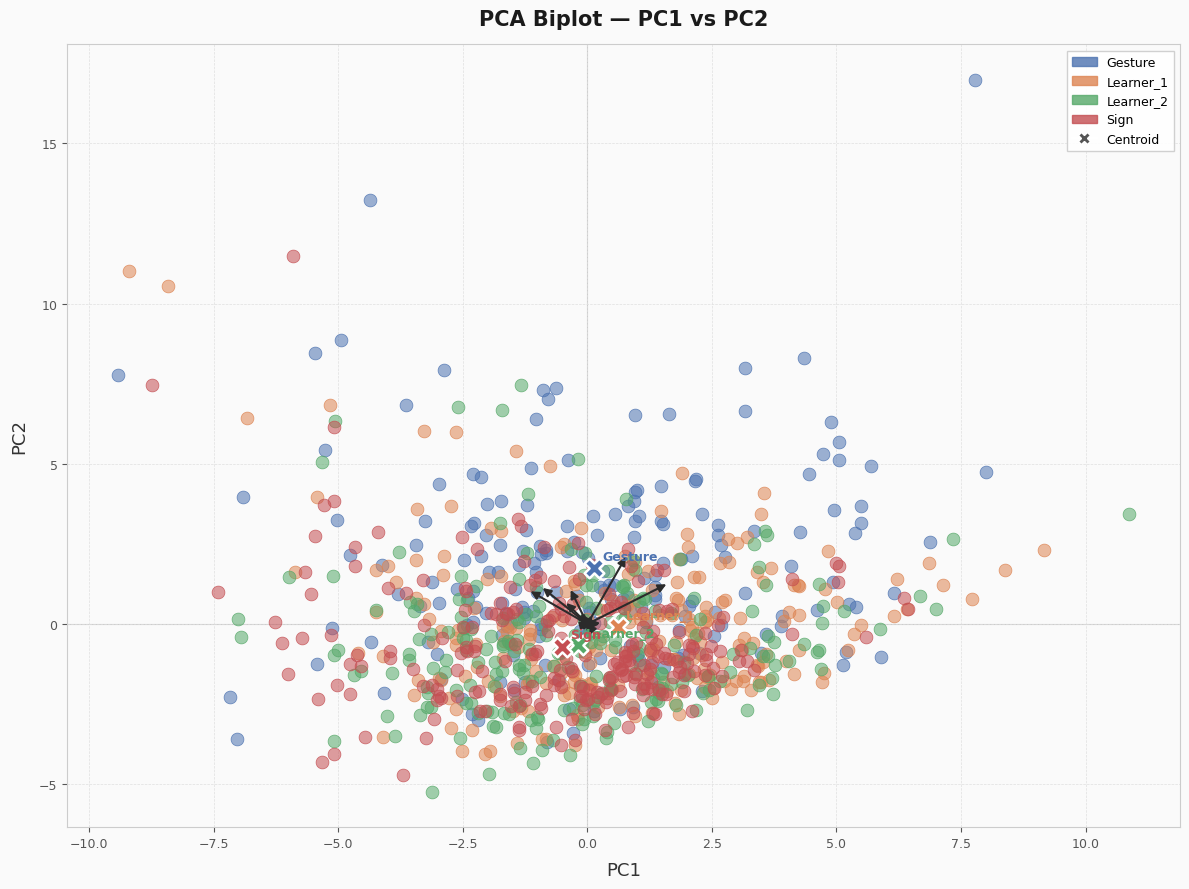

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC2_3_biplot.png


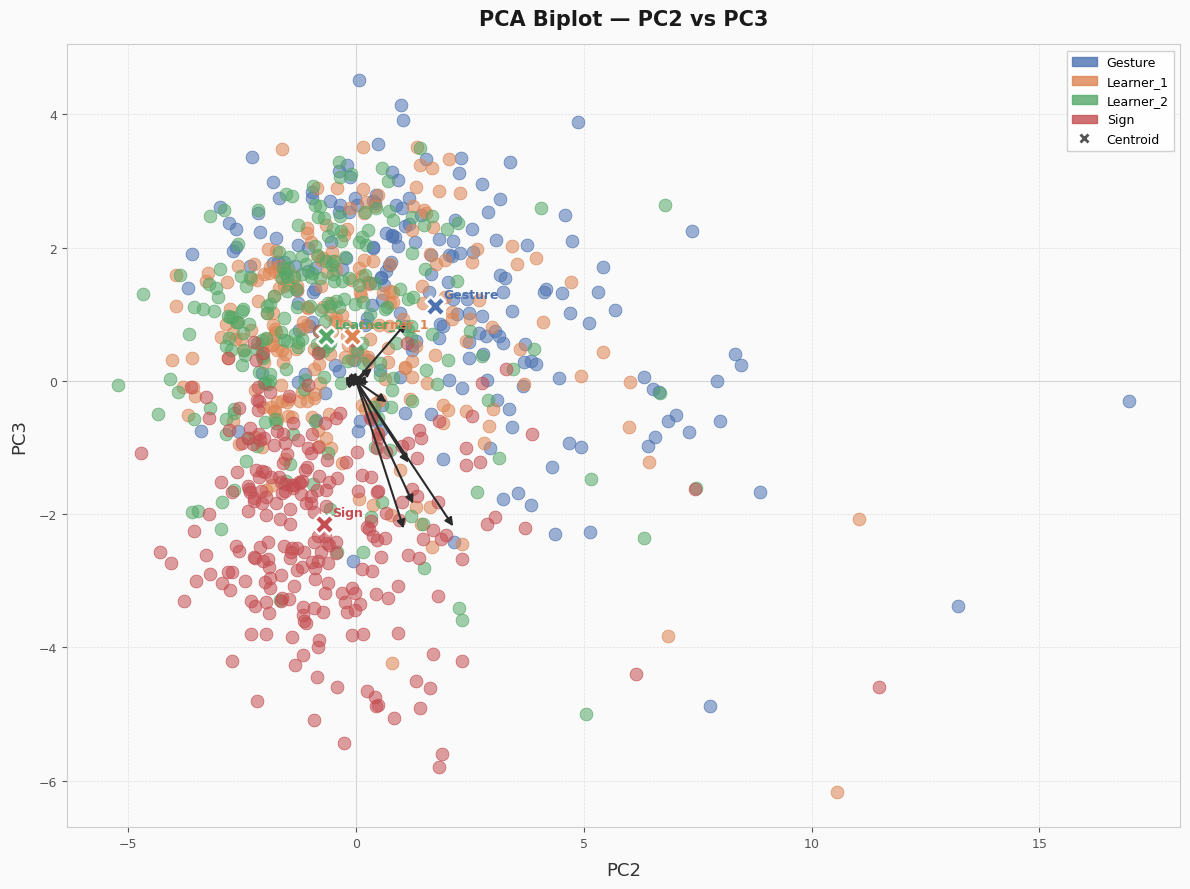

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC3_4_biplot.png


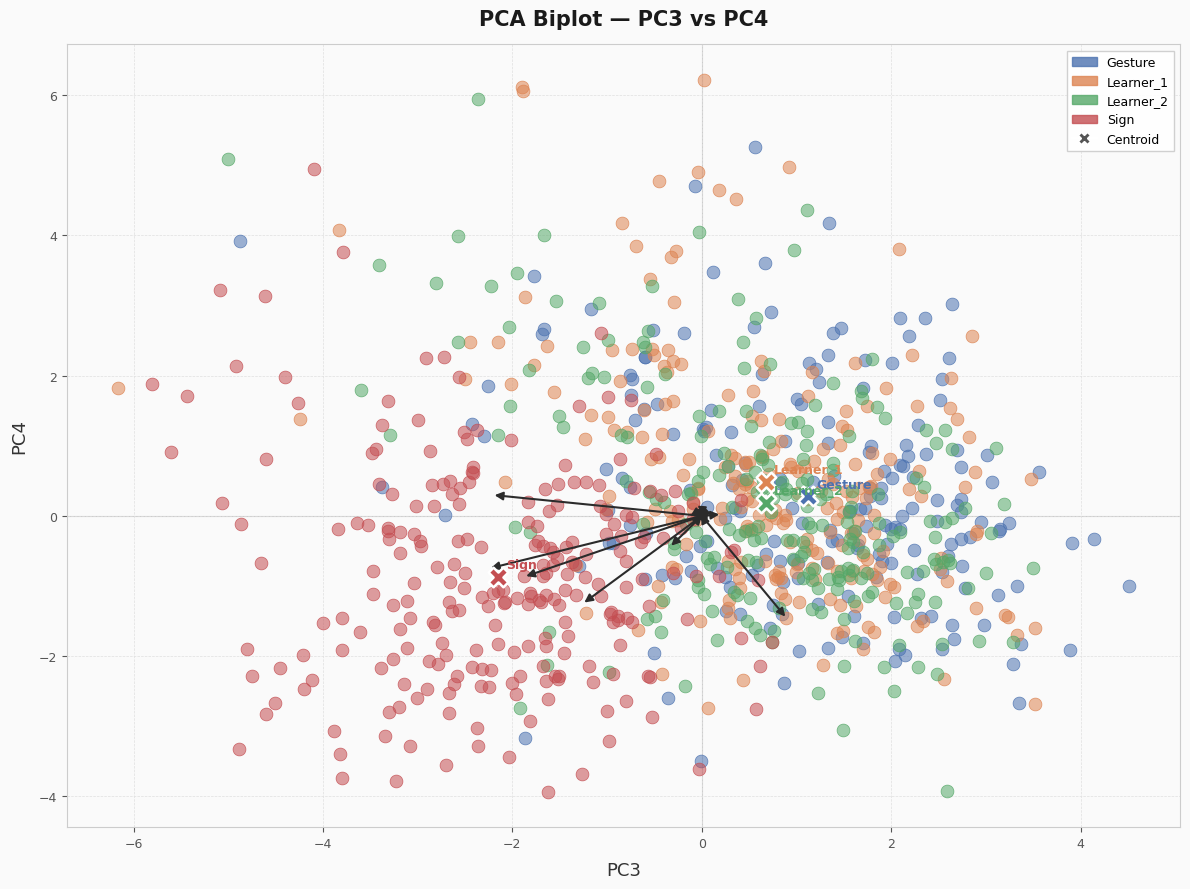

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC3 vs PC4'}, xlabel='PC3', ylabel='PC4'>)

In [140]:
# static 1-2
static_PCA_biplot(score=x_new_GSG, 
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                        le=le,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC1_2_biplot.png")
                    )

# static 2-3
static_PCA_biplot(score=x_new_GSG,
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, pc_y=3,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                        le=le,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC2_3_biplot.png")
                    )

# 3-4
static_PCA_biplot(score=x_new_GSG,
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, pc_y=4,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                        le=le,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC3_4_biplot.png")
                    )

## Bootstraping and significance

In [141]:
bootstrap_results_GSG = bootstrap_pca(Xz_GSG)
permutation_results_GSG = permutation_pca(Xz_GSG)

# determine significant PCs
var_explained_GSG = pca_GSG.explained_variance_ratio_
null_var_thresh_GSG = permutation_results_GSG["null_eig_thresh"] / np.sum(pca_GSG.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GSG = var_explained_GSG > null_var_thresh_GSG

# apply 5-10 % cut-off
sig_pc_effect_GSG = var_explained_GSG > 0.05  # 5% cut-off
sig_pc_GSG = sig_pc_null_GSG & sig_pc_effect_GSG

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GSG, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GSG[i-1]:.3f}")

Significant PCs:
PC1: significant = True, var explained = 0.230
PC2: significant = True, var explained = 0.179
PC3: significant = True, var explained = 0.109
PC4: significant = True, var explained = 0.079
PC5: significant = True, var explained = 0.052
PC6: significant = False, var explained = 0.043
PC7: significant = False, var explained = 0.041
PC8: significant = False, var explained = 0.038
PC9: significant = False, var explained = 0.034
PC10: significant = False, var explained = 0.028
PC11: significant = False, var explained = 0.026
PC12: significant = False, var explained = 0.022
PC13: significant = False, var explained = 0.019
PC14: significant = False, var explained = 0.019
PC15: significant = False, var explained = 0.017
PC16: significant = False, var explained = 0.013
PC17: significant = False, var explained = 0.011
PC18: significant = False, var explained = 0.008
PC19: significant = False, var explained = 0.007
PC20: significant = False, var explained = 0.007
PC21: significant

## Identify sig variables

In [142]:
df_sig_vars_GSG = identify_sigvar(pca_GSG, bootstrap_results_GSG, permutation_results_GSG, df_clean)
df_sig_vars_GSG[df_sig_vars_GSG["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
9,1,gross__magnitude__arm_acc_peak_mean,0.333613,6.797691,4.875657,8.309582,0.000267,0.201870,True
6,1,gross__rhythm__arm_speed_mod_depth,0.330185,6.658705,5.199539,7.858523,0.000250,0.208548,True
8,1,gross__variability__arm_acc_Gstd,0.325379,6.466280,4.343481,8.117193,0.000306,0.202414,True
13,1,gross__rhythm__arm_acc_mod_depth,0.320135,6.259540,4.727927,7.367196,0.000293,0.196854,True
2,1,gross__magnitude__arm_speed_peak_mean,0.315828,6.092255,3.689502,8.028271,0.000213,0.203586,True
...,...,...,...,...,...,...,...,...,...
305,9,gross__proxdist__proximalization_index,0.361811,0.178870,0.001804,0.491032,0.000143,0.149038,True
339,10,gross__proxdist__proximalization_index,0.692403,0.438692,0.027861,0.545014,0.000142,0.144131,True
337,10,gross__coordination__arm_coupling,-0.487608,0.217563,0.011851,0.334496,0.000193,0.139513,True
357,11,gross__smoothness__arm_sparc,0.527338,0.220581,0.010603,0.223926,0.000219,0.144797,True


In [143]:
sig_idx = np.where(sig_pc_GSG)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GSG[:, sig_idx], columns=pc_cols)

meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_gross.csv'), index=False)

## Filtered vs unfiltered loadings (per significant PC)

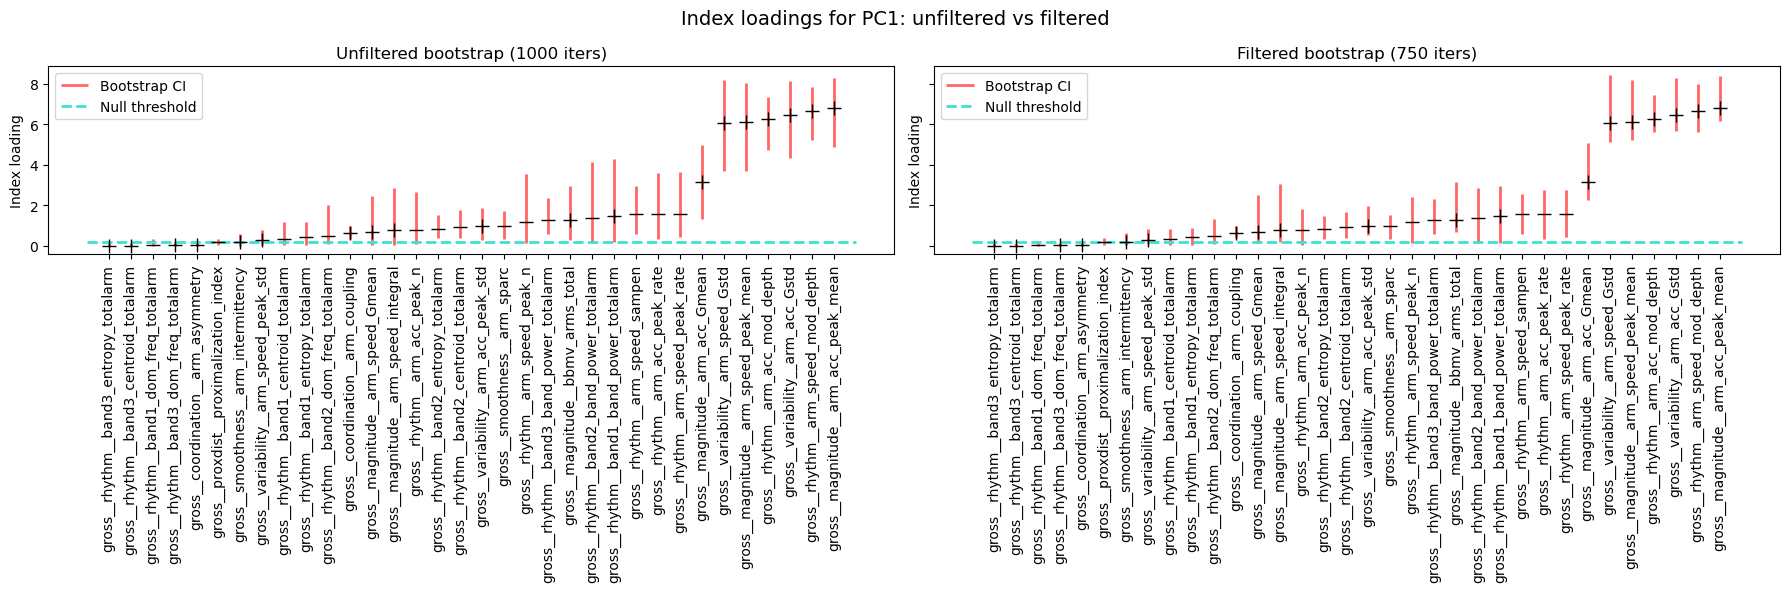

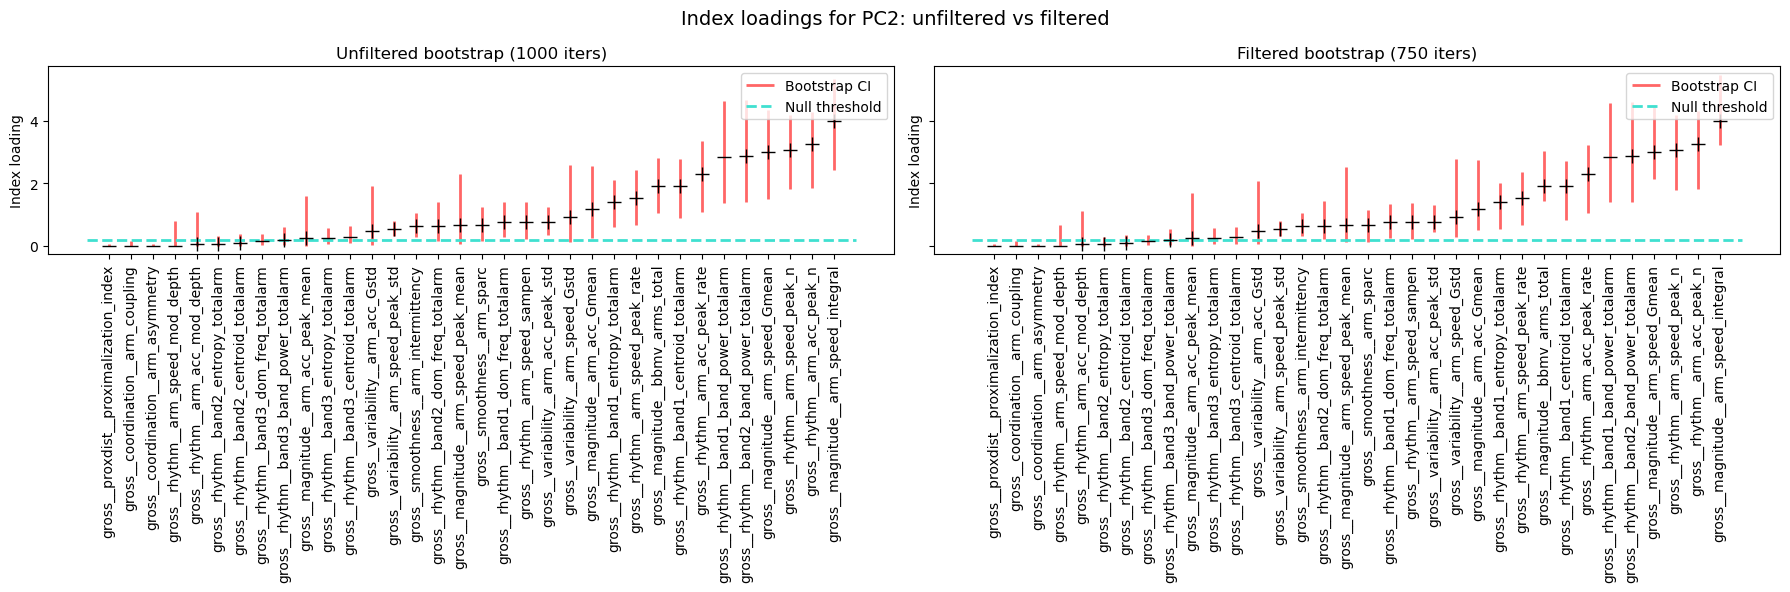

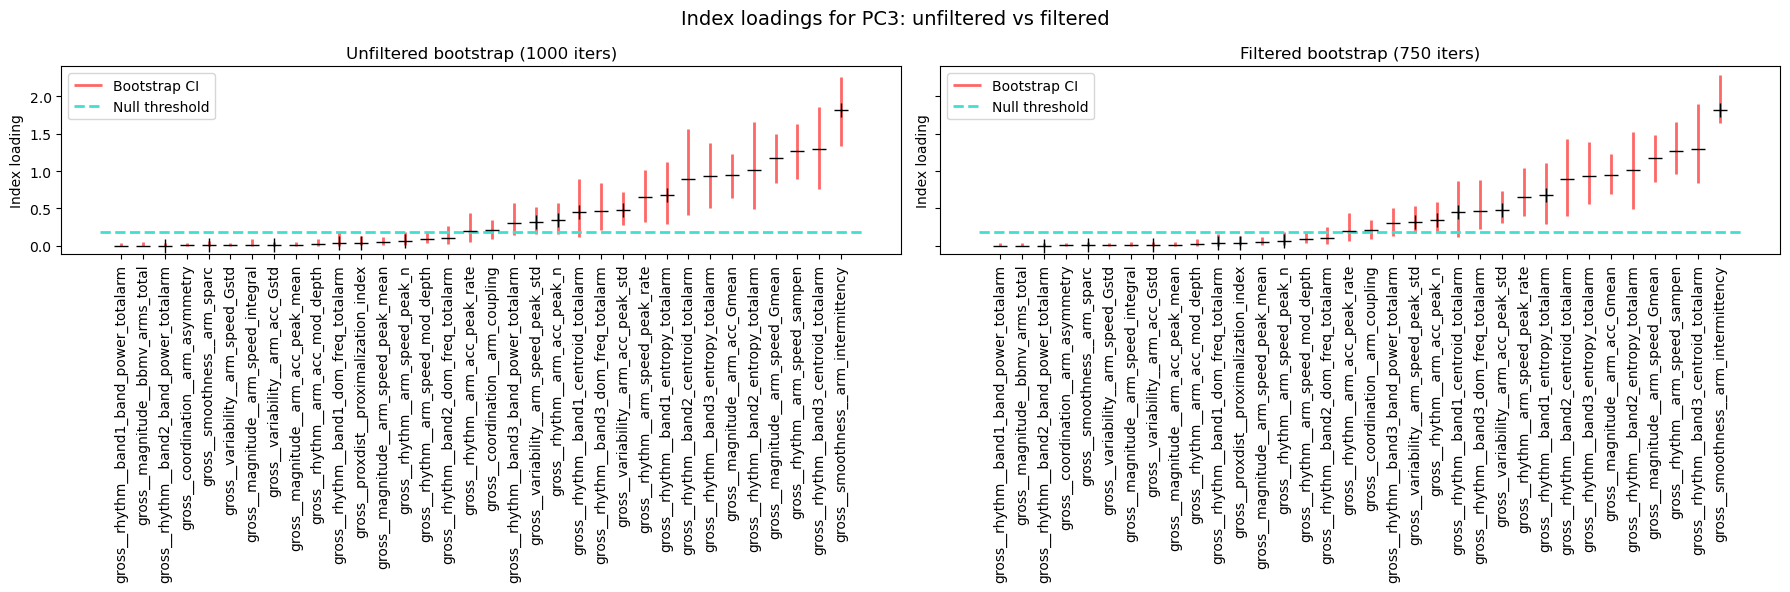

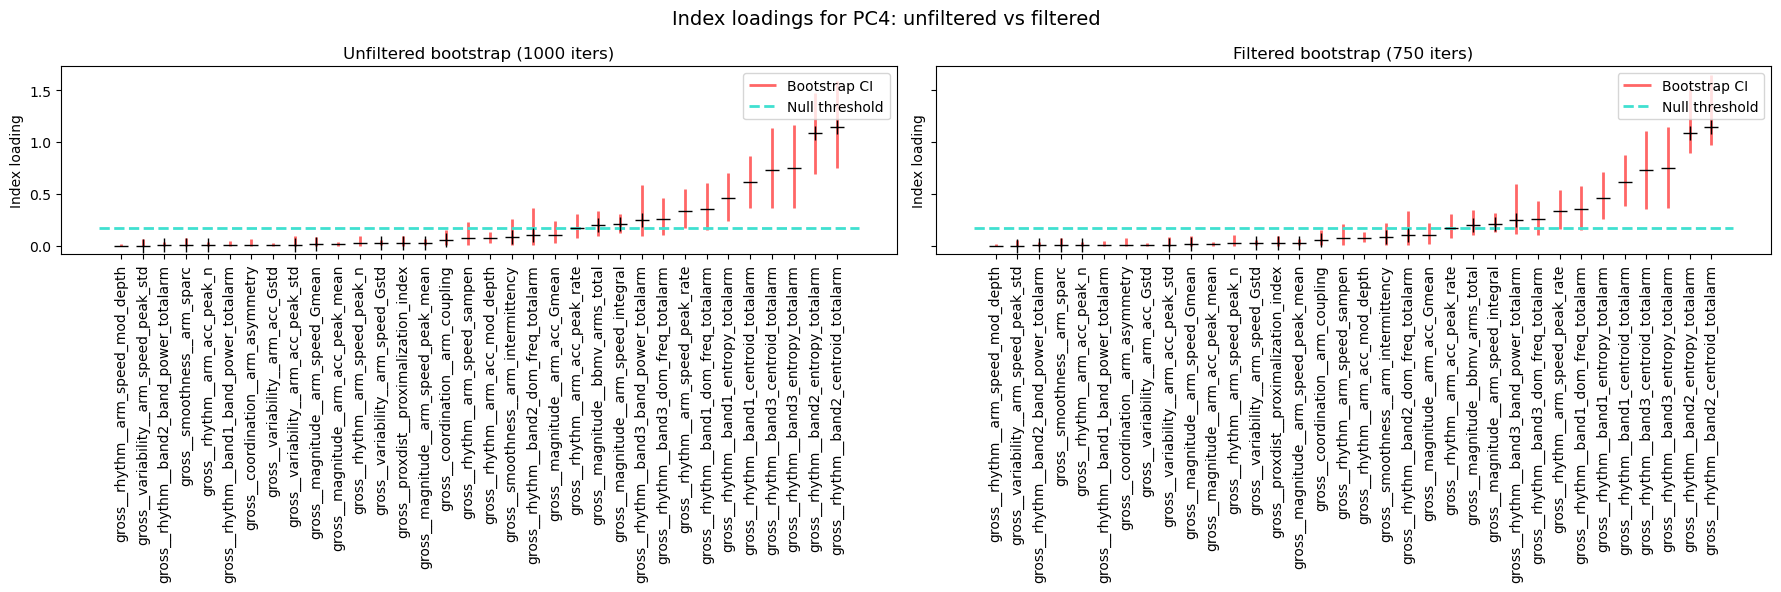

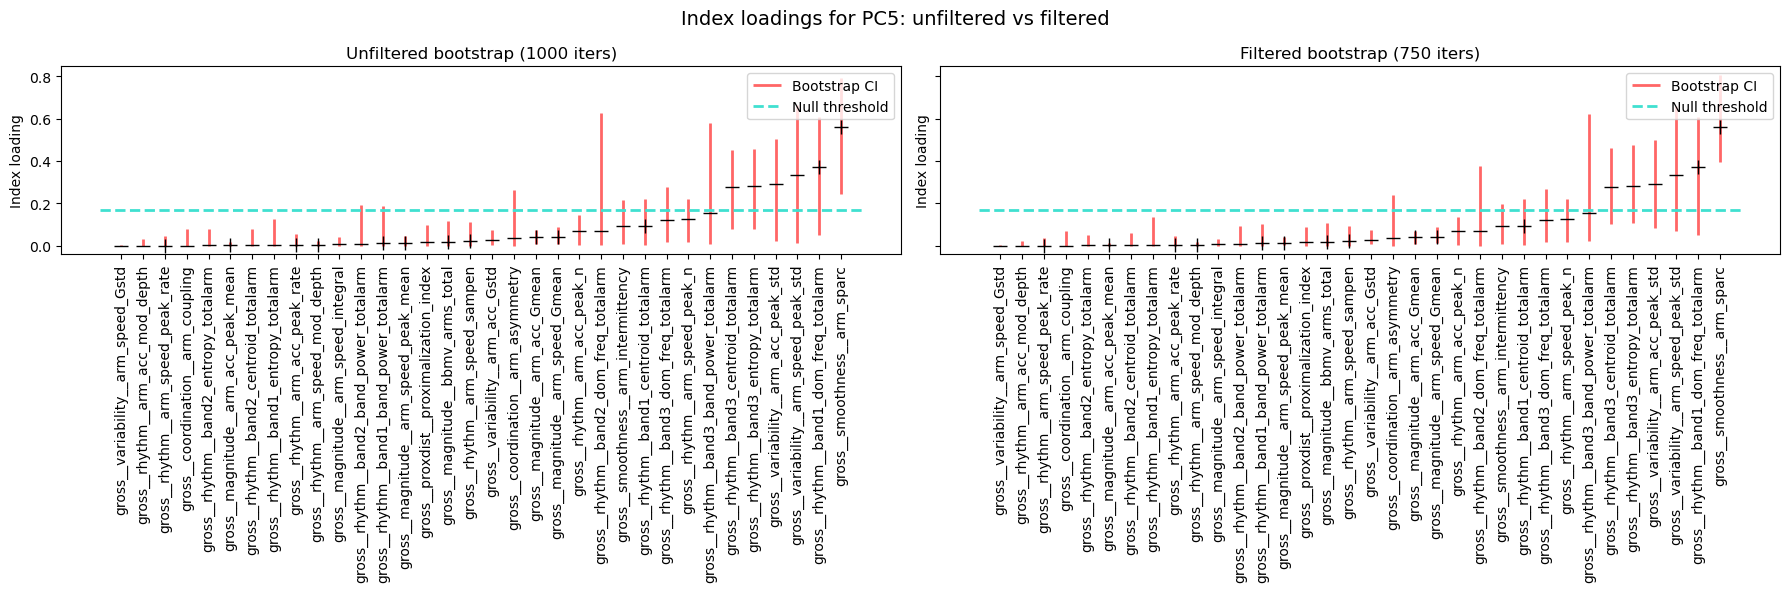

In [144]:
# Before vs after filtering, for EVERY significant PC (GSG / gross only)
for pc in np.where(sig_pc_GSG)[0]:
    plot_loadings_compare(pca_GSG, bootstrap_results_GSG, permutation_results_GSG,
                          pc_idx=int(pc), feature_names=df_clean.columns[:-1],
                          pc_name=f"PC{pc+1}")


## Features to keep (stability-aware: significant + CI vs null before/after)

In [145]:
# Stability-aware table for every significant PC (GSG / gross only).
# Same shape as GS (loadings_all.csv); becomes the authoritative loadings file for this group,
# superseding the simple export_sigvars written above.
sig_pcs = np.where(sig_pc_GSG)[0]                      # 0-based significant PC indices
tables = []
for pc in sig_pcs:
    tbl, _ = select_features_for_pc(pca_GSG, bootstrap_results_GSG, permutation_results_GSG,
                                    df_clean.columns[:-1], pc_idx=pc, verbose=False)
    tables.append(tbl.assign(PC=pc + 1))

sig_features_GSG = pd.concat(tables, ignore_index=True)

# keep ALL significant features; flag CI-vs-null status before and after stabilization
sig_features_GSG = (sig_features_GSG[sig_features_GSG["sig_obs"]]
                   .rename(columns={"stable_unfilt": "CI_above_null_before",
                                    "stable_filt":   "CI_above_null_after"})
                   [["PC", "variable", "loading_sign", "obs_index",
                     "null_thresh",
                     "boot_low_unfilt", "boot_high_unfilt",
                     "boot_low_filt",  "boot_high_filt",
                     "CI_above_null_before", "CI_above_null_after",
                     "is_anchor", "share",
                      "cum_frac", "within_50pct"]]
                   .sort_values(["PC", "obs_index"], ascending=[True, False])
                   .reset_index(drop=True))

sig_features_GSG.to_csv(os.path.join("Datasets", "loadings_gross.csv"), index=False)
sig_features_GSG


,PC,variable,loading_sign,obs_index,null_thresh,boot_low_unfilt,boot_high_unfilt,boot_low_filt,boot_high_filt,CI_above_null_before,CI_above_null_after,is_anchor,share,cum_frac,within_50pct
0,1,gross__magnitude__arm_acc_peak_mean,1.0,6.797691,0.201870,4.875657,8.309582,6.161721,8.405942,True,True,True,0.111297,0.111297,True
1,1,gross__rhythm__arm_speed_mod_depth,1.0,6.658705,0.208548,5.199539,7.858523,5.621514,7.978962,True,True,False,0.109022,0.220319,True
2,1,gross__variability__arm_acc_Gstd,1.0,6.466280,0.202414,4.343481,8.117193,5.674598,8.273735,True,True,False,0.105871,0.326191,True
3,1,gross__rhythm__arm_acc_mod_depth,1.0,6.259540,0.196854,4.727927,7.367196,5.615092,7.458984,True,True,False,0.102486,0.428677,True
4,1,gross__magnitude__arm_speed_peak_mean,1.0,6.092255,0.203586,3.689502,8.028271,5.226179,8.192272,True,True,False,0.099747,0.528424,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,5,gross__rhythm__band1_dom_freq_totalarm,1.0,0.372142,0.187541,0.049576,0.607350,0.050893,0.608574,False,False,False,0.120757,0.303354,True
85,5,gross__variability__arm_speed_peak_std,-1.0,0.331462,0.171330,0.013626,0.664903,0.067668,0.662097,False,False,False,0.107557,0.410911,True
86,5,gross__variability__arm_acc_peak_std,-1.0,0.289440,0.151732,0.023949,0.502608,0.082163,0.499118,False,False,False,0.093921,0.504832,False
87,5,gross__rhythm__band3_entropy_totalarm,-1.0,0.280249,0.163177,0.077970,0.456936,0.105875,0.473486,False,False,False,0.090939,0.595771,False


# PCA: All groups (fine only)

In [146]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [147]:
# get rid of all columns with fine_ in the name
cols_to_drop = [col for col in df_clean.columns if col.startswith('gross_')]

df_clean = df_clean.drop(columns=cols_to_drop)

In [148]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features

df_clean['groupID'] = df_clean['groupID'].astype('category')
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GSF = StandardScaler()
Xz_GSF = scaler_GSF.fit_transform(X)    

# PCA transformation
pca_GSF = PCA()
x_new_GSF = pca_GSF.fit_transform(Xz_GSF)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GSF = pca_GSF.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # PC1 and PC2 (the PCs you plot below)
    component = loadings_GSF[:, i]      # column i = all variables' loadings ON PC i
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength                    )

In [149]:
# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, pc_y=3,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength 
                       )

In [150]:
# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, pc_y=4,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength 
                       )

## Bootstraping and significance

In [151]:
bootstrap_results_GSF = bootstrap_pca(Xz_GSF)
permutation_results_GSF = permutation_pca(Xz_GSF)

# determine significant PCs
var_explained_GSF = pca_GSF.explained_variance_ratio_
null_var_thresh_GSF = permutation_results_GSF["null_eig_thresh"] / np.sum(pca_GSF.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GSF = var_explained_GSF > null_var_thresh_GSF

sig_pc_effect_GSF = var_explained_GSF > 0.05  # 5% cut-off
sig_pc_GSF = sig_pc_null_GSF & sig_pc_effect_GSF

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GSF, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GSF[i-1]:.3f}")



Significant PCs:
PC1: significant = True, var explained = 0.358
PC2: significant = True, var explained = 0.140
PC3: significant = True, var explained = 0.128
PC4: significant = True, var explained = 0.073
PC5: significant = True, var explained = 0.070
PC6: significant = False, var explained = 0.059
PC7: significant = False, var explained = 0.049
PC8: significant = False, var explained = 0.034
PC9: significant = False, var explained = 0.028
PC10: significant = False, var explained = 0.022
PC11: significant = False, var explained = 0.017
PC12: significant = False, var explained = 0.010
PC13: significant = False, var explained = 0.009
PC14: significant = False, var explained = 0.002
PC15: significant = False, var explained = 0.001
PC16: significant = False, var explained = 0.000


## Identify sig variables

In [152]:
df_sig_vars_GSF = identify_sigvar(pca_GSF, bootstrap_results_GSF, permutation_results_GSF, df_clean)
df_sig_vars_GSF[df_sig_vars_GSF["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
2,1,fine__handshape__thumb_index_mean,0.355990,4.159583,2.302475,7.341914,0.000478,0.284573,True
0,1,fine__handshape__fingertip_spread_mean,0.354611,4.127433,2.718622,6.242484,0.000310,0.314140,True
1,1,fine__variability__fingertip_spread_std,0.345241,3.912181,1.983820,7.452767,0.000394,0.326226,True
10,1,fine__variability__handshape_variability,0.327391,3.518097,2.142804,5.611239,0.000880,0.294135,True
3,1,fine__variability__thumb_index_std,0.327301,3.516169,1.951406,5.786605,0.000389,0.329158,True
4,1,fine__handshape__mcp_tip_mean,0.317785,3.314678,1.588149,6.612580,0.000290,0.306949,True
5,1,fine__variability__mcp_tip_std,0.281428,2.599614,0.866929,6.209464,0.000325,0.318881,True
11,1,fine__magnitude__flexion_speed_mean,0.264588,2.297817,0.956497,4.617849,0.000607,0.285993,True
12,1,fine__variability__flexion_speed_std,0.242106,1.923910,0.690096,4.301769,0.000523,0.337602,True
6,1,fine__handshape__thumb_opposition_mean,0.229785,1.733075,1.263604,2.256715,0.000588,0.318337,True


In [153]:
sig_idx = np.where(sig_pc_GSF)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GSF[:, sig_idx], columns=pc_cols)

meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_fine.csv'), index=False)

## Filtered vs unfiltered loadings (per significant PC)

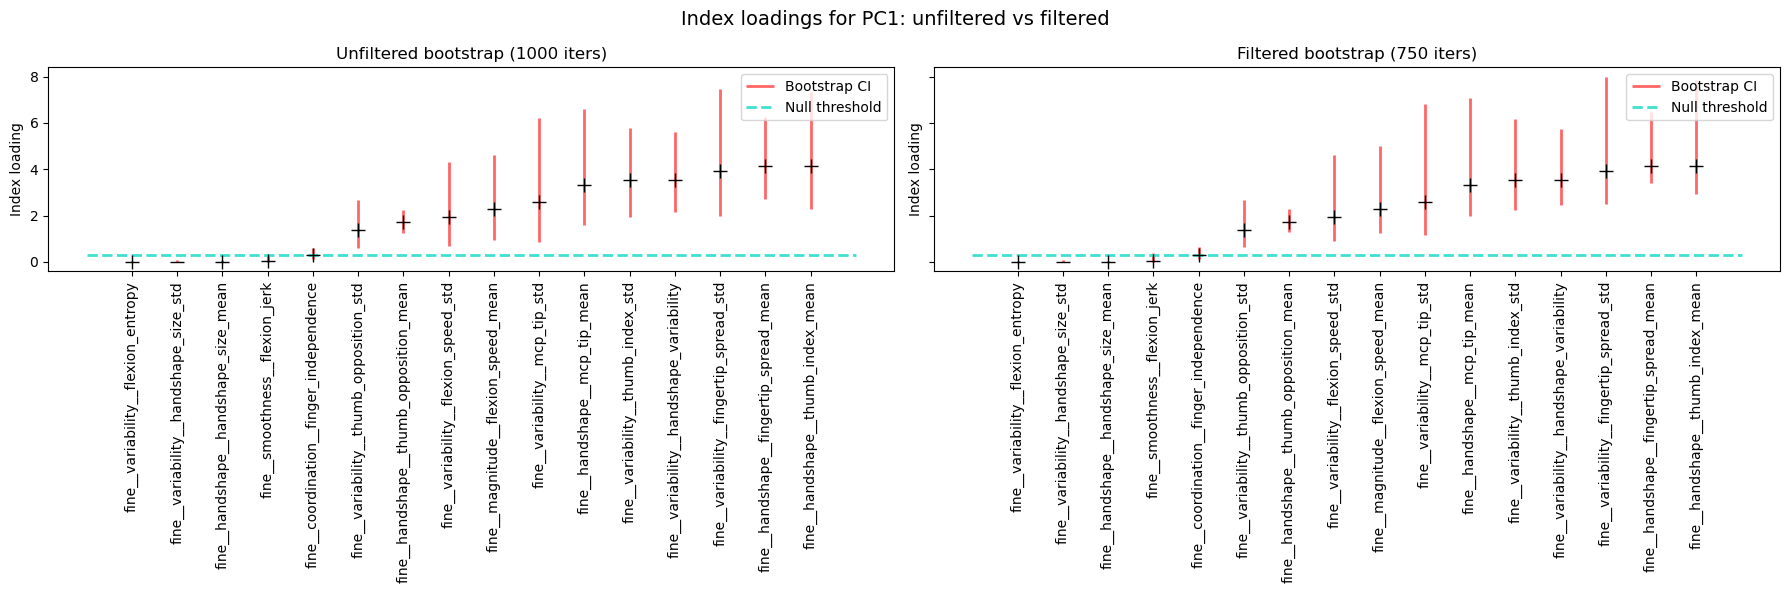

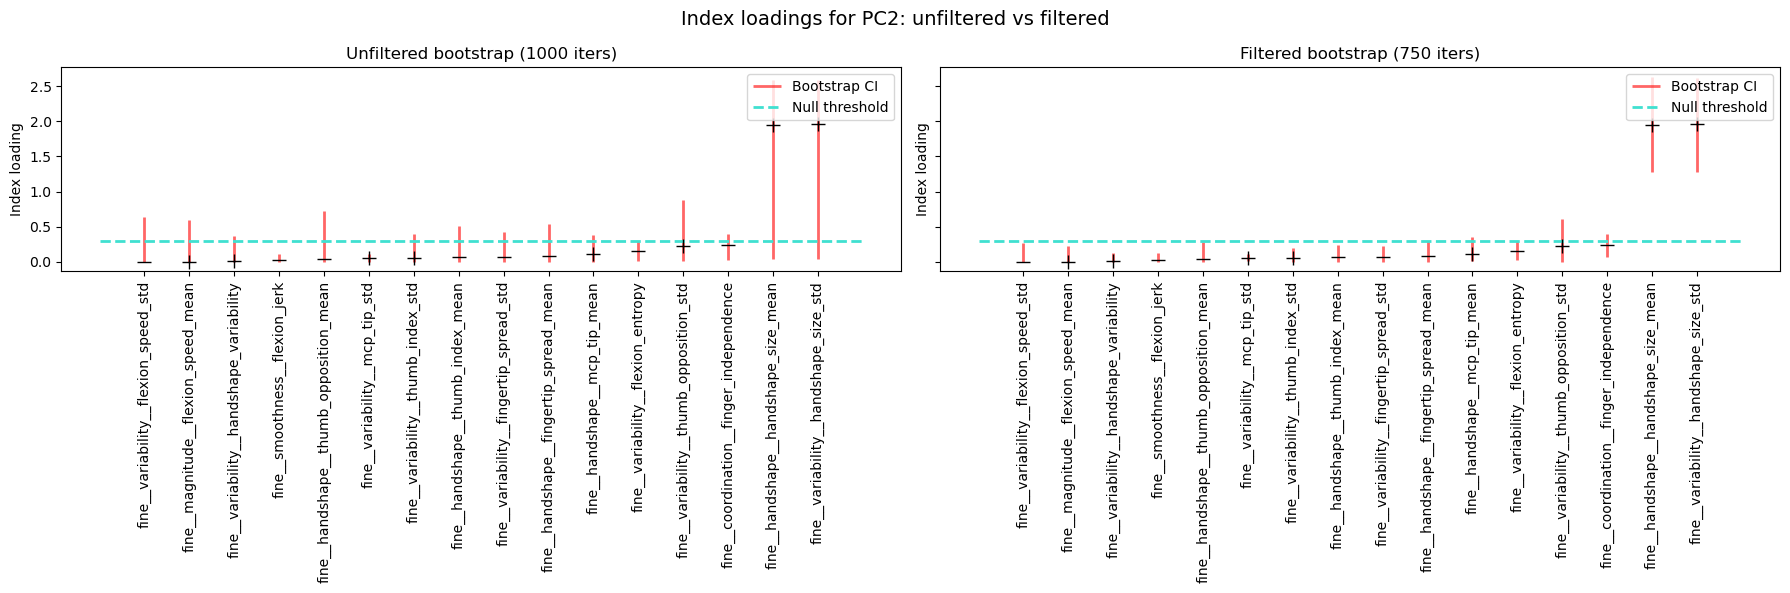

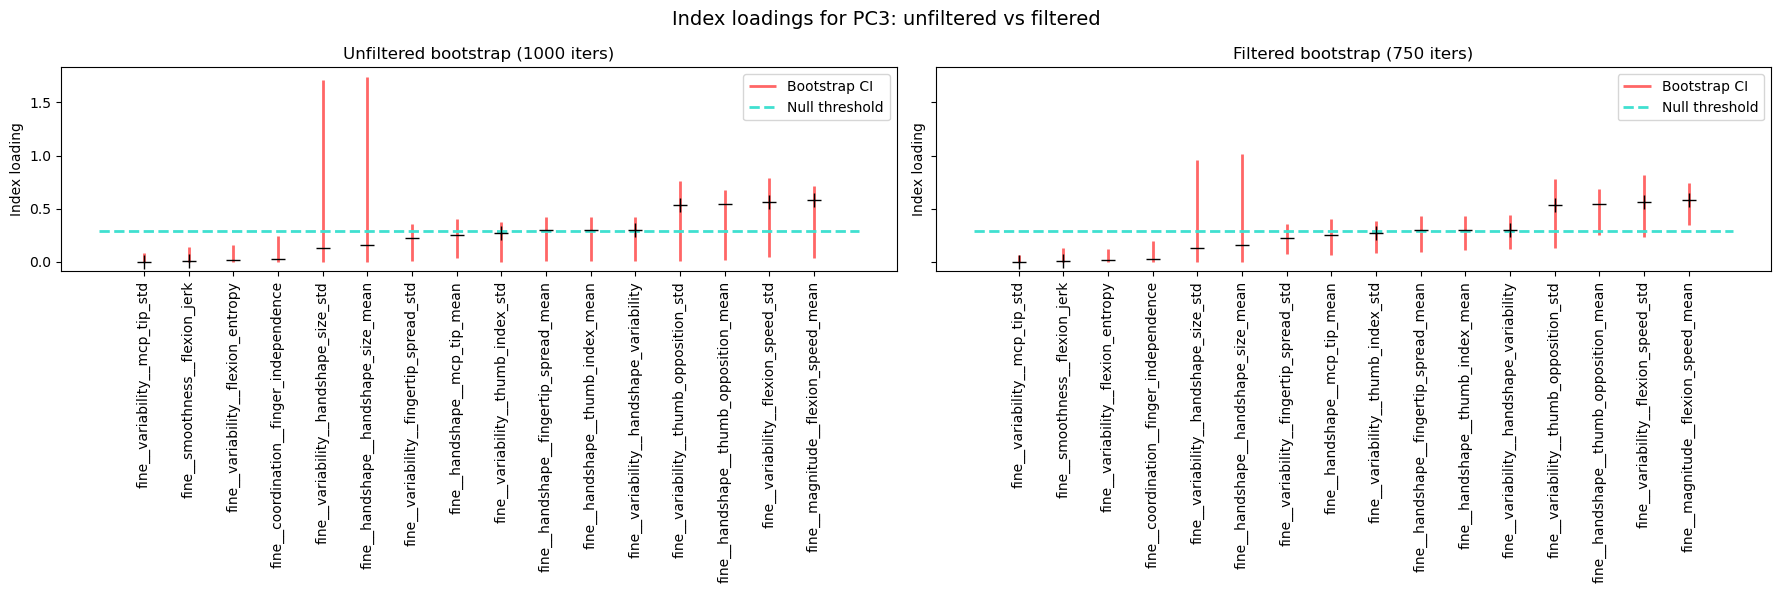

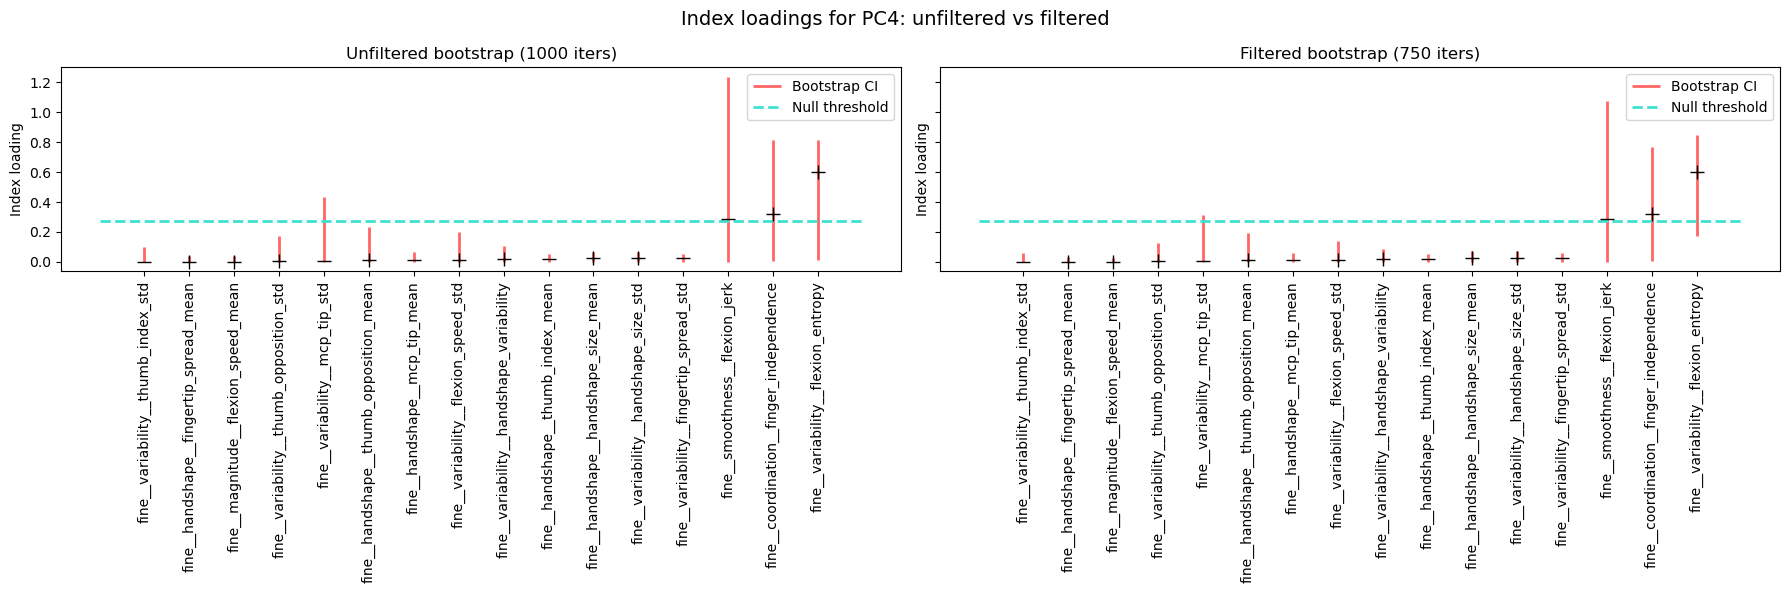

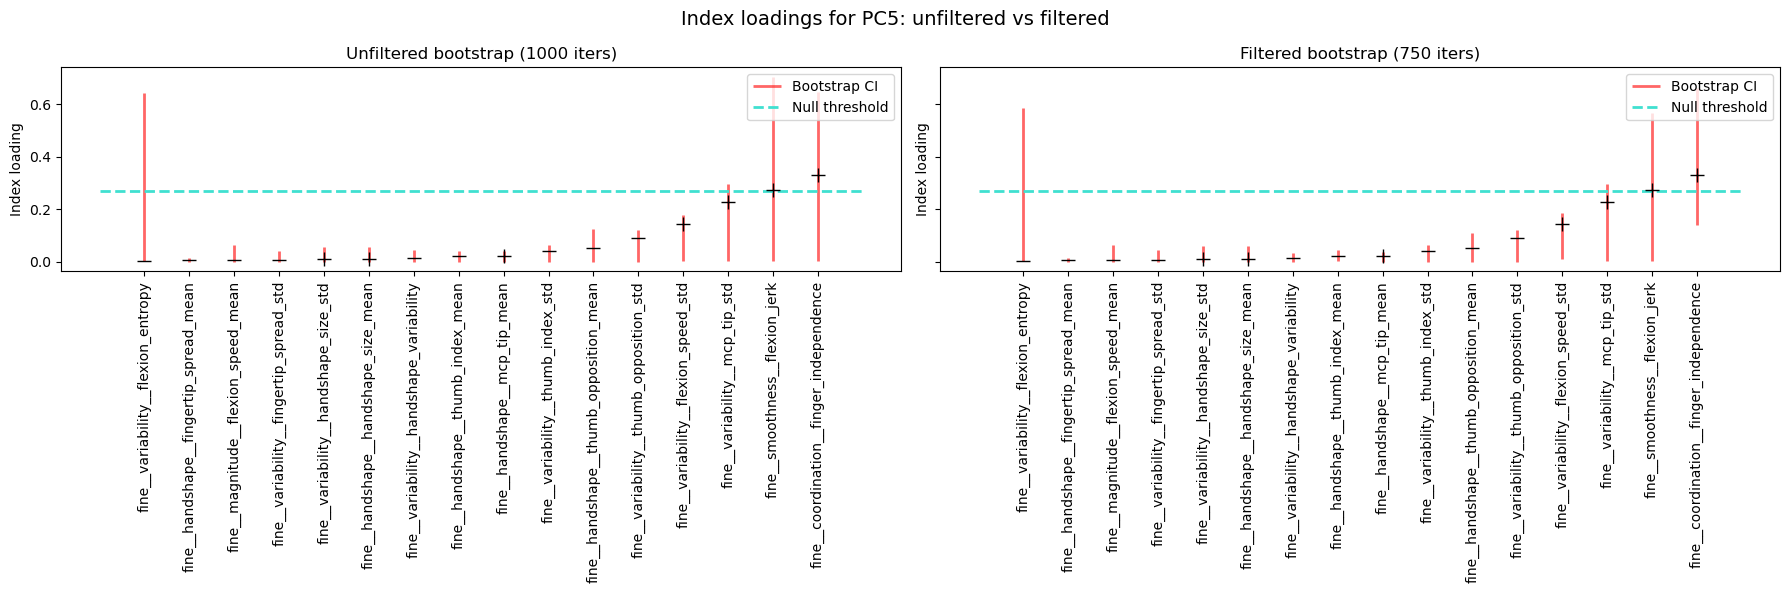

In [154]:
# Before vs after filtering, for EVERY significant PC (GSF / fine only)
for pc in np.where(sig_pc_GSF)[0]:
    plot_loadings_compare(pca_GSF, bootstrap_results_GSF, permutation_results_GSF,
                          pc_idx=int(pc), feature_names=df_clean.columns[:-1],
                          pc_name=f"PC{pc+1}")


## Features to keep (stability-aware: significant + CI vs null before/after)

In [155]:
# Stability-aware table for every significant PC (GSF / fine only).
# Same shape as GS (loadings_all.csv); becomes the authoritative loadings file for this group,
# superseding the simple export_sigvars written above.
sig_pcs = np.where(sig_pc_GSF)[0]                      # 0-based significant PC indices
tables = []
for pc in sig_pcs:
    tbl, _ = select_features_for_pc(pca_GSF, bootstrap_results_GSF, permutation_results_GSF,
                                    df_clean.columns[:-1], pc_idx=pc, verbose=False)
    tables.append(tbl.assign(PC=pc + 1))

sig_features_GSF = pd.concat(tables, ignore_index=True)

# keep ALL significant features; flag CI-vs-null status before and after stabilization
sig_features_GSF = (sig_features_GSF[sig_features_GSF["sig_obs"]]
                   .rename(columns={"stable_unfilt": "CI_above_null_before",
                                    "stable_filt":   "CI_above_null_after"})
                   [["PC", "variable", "loading_sign", "obs_index",
                     "null_thresh",
                     "boot_low_unfilt", "boot_high_unfilt",
                     "boot_low_filt",  "boot_high_filt",
                     "CI_above_null_before", "CI_above_null_after",
                     "is_anchor", "share",
                      "cum_frac", "within_50pct"]]
                   .sort_values(["PC", "obs_index"], ascending=[True, False])
                   .reset_index(drop=True))

sig_features_GSF.to_csv(os.path.join("Datasets", "loadings_fine.csv"), index=False)
sig_features_GSF


,PC,variable,loading_sign,obs_index,null_thresh,boot_low_unfilt,boot_high_unfilt,boot_low_filt,boot_high_filt,CI_above_null_before,CI_above_null_after,is_anchor,share,cum_frac,within_50pct
0,1,fine__handshape__thumb_index_mean,1.0,4.159583,0.284573,2.302475,7.341914,2.930551,7.847539,True,True,False,0.126729,0.126729,True
1,1,fine__handshape__fingertip_spread_mean,1.0,4.127433,0.314140,2.718622,6.242484,3.398190,6.491237,True,True,True,0.125749,0.252478,True
2,1,fine__variability__fingertip_spread_std,1.0,3.912181,0.326226,1.983820,7.452767,2.487064,8.000752,True,True,False,0.119191,0.371669,True
3,1,fine__variability__handshape_variability,1.0,3.518097,0.294135,2.142804,5.611239,2.437536,5.757016,True,True,False,0.107185,0.478854,True
4,1,fine__variability__thumb_index_std,1.0,3.516169,0.329158,1.951406,5.786605,2.219839,6.170340,True,True,False,0.107126,0.585980,False
5,1,fine__handshape__mcp_tip_mean,1.0,3.314678,0.306949,1.588149,6.612580,1.970461,7.083348,True,True,False,0.100987,0.686967,False
6,1,fine__variability__mcp_tip_std,1.0,2.599614,0.318881,0.866929,6.209464,1.142223,6.810522,True,True,False,0.079202,0.766168,False
7,1,fine__magnitude__flexion_speed_mean,1.0,2.297817,0.285993,0.956497,4.617849,1.241684,4.988355,True,True,False,0.070007,0.836175,False
8,1,fine__variability__flexion_speed_std,1.0,1.923910,0.337602,0.690096,4.301769,0.896150,4.612496,True,True,False,0.058615,0.894790,False
9,1,fine__handshape__thumb_opposition_mean,1.0,1.733075,0.318337,1.263604,2.256715,1.276011,2.295435,True,True,False,0.052801,0.947591,False


# Summary across all three groups

In [156]:
# Combined stability summary across all three groups (uses the three sig_features_* tables)
summary_all = pd.concat([
    sig_features_GS.assign(group="all"),
    sig_features_GSG.assign(group="gross"),
    sig_features_GSF.assign(group="fine"),
], ignore_index=True)

# per group x PC: how many features are significant, and how many keep their CI above null
overview = (summary_all
            .groupby(["group", "PC"])
            .agg(n_significant=("variable", "size"),
                 CI_above_null_before=("CI_above_null_before", "sum"),
                 CI_above_null_after=("CI_above_null_after", "sum"))
            .reset_index())

summary_all.to_csv(os.path.join("Datasets", "loadings_all_groups.csv"), index=False)
overview


,group,PC,n_significant,CI_above_null_before,CI_above_null_after
0,all,1,33,16,18
1,all,2,37,2,15
2,all,3,28,1,11
3,all,4,27,13,14
4,all,5,12,4,5
5,fine,1,12,11,11
6,fine,2,2,0,2
7,fine,3,6,0,1
8,fine,4,3,0,0
9,fine,5,1,0,0


# Varimax (rotated) analysis for all three PCAs

Adds, for each PCA block, (1) a check of whether varimax meaningfully changes the retained components and (2) a re-derivation of loading significance on the rotated solution — rotating the same bootstrap/null draws, aligning replicates, and using the rotated column sum-of-squares as the eigenvalue analog. Rotated scores are standardized before rotation so they stay orthogonal for the brms stage.

In [157]:
# ============================================================
# VARIMAX add-on: rotation check + rotated-loading significance
# Reusable across the three PCA blocks (GS = all, GSG = gross, GSF = fine).
# ------------------------------------------------------------
# Note on "loadings": this notebook uses pca.components_.T (unit eigenvectors),
# and its index loading = components**2 * eig**2 = (V*sqrt(lam))**2 * lam = L**2 * lam,
# so the eigenvalue weighting is already baked in and the obs-vs-null test is
# internally consistent. Varimax is the one place the distinction matters:
# rotation must act on the properly scaled loadings L = V * sqrt(lam).
# ============================================================
import numpy as np, pandas as pd
from numpy.linalg import svd
from scipy.optimize import linear_sum_assignment

def scaled_loadings(pca, k):
    return pca.components_.T[:, :k] * np.sqrt(pca.explained_variance_[:k])

def varimax(L, normalize=True, max_iter=500, tol=1e-8):
    """Kaiser-normalized varimax (MATLAB rotatefactors / factor_analyzer default).
    Returns (rotated loadings, rotation R) with L_rot = L @ R."""
    L = np.asarray(L, float).copy(); pfeat, k = L.shape
    if k < 2: return L, np.eye(k)
    if normalize:
        h = np.sqrt((L**2).sum(1)); h[h == 0] = 1.0; L = L / h[:, None]
    R, d = np.eye(k), 0.0
    for _ in range(max_iter):
        d_old = d; Lam = L @ R
        B = L.T @ (Lam**3 - (Lam @ np.diag((Lam**2).sum(0))) / pfeat)
        u, s, vt = svd(B); R = u @ vt; d = s.sum()
        if d_old != 0 and abs(d - d_old) / d_old < tol: break
    Lam = L @ R
    if normalize: Lam = Lam * h[:, None]
    return Lam, R

def _align(L_ref, L_rot):
    """Match rotated columns to reference (Hungarian on |corr|) + sign-flip."""
    k = L_ref.shape[1]
    C = np.array([[abs(np.corrcoef(L_ref[:, a], L_rot[:, b])[0, 1]) for b in range(k)]
                  for a in range(k)])
    _, c = linear_sum_assignment(-C); A = L_rot[:, c].copy()
    for a in range(k):
        if np.dot(L_ref[:, a], A[:, a]) < 0: A[:, a] *= -1
    return A

def _tucker(a, b):
    return np.dot(a, b) / (np.sqrt(np.dot(a, a)) * np.sqrt(np.dot(b, b)))

def simple_structure(L, thresh=0.30):
    L2 = L**2; rs = L2.sum(1); rs[rs == 0] = np.nan
    return (np.nanmean(rs**2 / (L2**2).sum(1)),
            (np.abs(L) < thresh).mean(), L2.var(0).sum())

def feat_names(df_sig_vars):
    """Recover ordered feature list for a block from its df_sig_vars table
    (robust to df_clean being mutated later in the notebook)."""
    return df_sig_vars.loc[df_sig_vars["PC"] == 1, "feature"].tolist()

def varimax_report(pca, x_new, sig_pc, feature_names, label="", thresh=0.30):
    """Does varimax change the retained PCs? Unrotated vs rotated diagnostics."""
    k = int(np.sum(sig_pc)); print(f"=== {label}: retained PCs k = {k} ===")
    if k < 2:
        print("k < 2 -> rotation trivial; nothing to test.\n"); return None
    fn = np.asarray(feature_names)
    L = scaled_loadings(pca, k); Lr, R = varimax(L); Lr_al = _align(L, Lr)
    c0, h0, v0 = simple_structure(L, thresh); c1, h1, v1 = simple_structure(Lr, thresh)
    cong = np.array([_tucker(L[:, i], Lr_al[:, i]) for i in range(k)])
    rel = np.abs(L).max(1) >= thresh
    moved = (np.argmax(np.abs(L), 1) != np.argmax(np.abs(Lr_al), 1)) & rel
    T = x_new[:, :k] / np.sqrt(pca.explained_variance_[:k]); scores_rot = T @ R  # standardized -> orthogonal
    off = np.corrcoef(scores_rot.T)[~np.eye(k, dtype=bool)]
    print(f"  complexity (->1) {c0:.3f} -> {c1:.3f} | hyperplane {h0:.2f} -> {h1:.2f}")
    print(f"  per-axis congruence {np.array2string(cong, precision=3)}  (min {cong.min():.3f})")
    print(f"  features changing primary PC: {int(moved.sum())} of {int(rel.sum())} (|L|>={thresh})")
    print(f"  rotated scores orthogonal? max |off-diag corr| = {np.abs(off).max():.1e}")
    if moved.sum() == 0 and cong.min() > 0.95 and (c0 - c1) < 0.05:
        print("  VERDICT: varimax does ~nothing -> keep unrotated.\n")
    else:
        print("  VERDICT: varimax restructures -> report rotated IF axes read cleaner.\n")
    return dict(k=k, L=L, L_rot=Lr_al, R=R, congruence=cong,
                moved=fn[moved].tolist(), scores_rot=scores_rot)

def varimax_significance(pca, bootstrap_results, permutation_results, sig_pc,
                         feature_names, loadings_confint=0.9, null_pool_columns=True):
    """Rotated-loading significance (mirror of identify_sigvar; RC = rotated component).
    Rotates the SAME bootstrap/null draws; aligns each replicate to the full-sample
    rotated reference; weights by the rotated column SS (= rotated eigenvalue analog)."""
    k = int(np.sum(sig_pc)); fn = list(feature_names)
    if k < 2:
        print("k < 2 -> no rotated significance."); return None
    half = (1 - loadings_confint) / 2; lowq, highq = 100 * half, 100 * (1 - half)
    L_ref, _ = varimax(scaled_loadings(pca, k))
    rot_index = lambda Lr: (Lr**2) * (Lr**2).sum(0)      # L_rot^2 * lambda_rot
    obs = rot_index(L_ref)
    BL, BE = bootstrap_results["boot_loadings"], bootstrap_results["boot_eigs"]
    NL, NE = permutation_results["null_loadings"], permutation_results["null_eigs"]
    boot = np.array([rot_index(_align(L_ref, varimax(BL[b][:, :k] * np.sqrt(BE[b][:k]))[0]))
                     for b in range(BL.shape[0])])
    null = np.array([rot_index(_align(L_ref, varimax(NL[b][:, :k] * np.sqrt(NE[b][:k]))[0]))
                     for b in range(NL.shape[0])])
    boot_low  = np.percentile(boot, lowq,  axis=0)
    boot_high = np.percentile(boot, highq, axis=0)
    if null_pool_columns:
        nt = np.percentile(null.transpose(1, 0, 2).reshape(len(fn), -1), highq, axis=1)
        null_thresh = np.repeat(nt[:, None], k, axis=1)
    else:
        null_thresh = np.percentile(null, highq, axis=0)
    rows = [dict(RC=pc + 1, variable=fn[f], loading=L_ref[f, pc],
                 loading_sign=np.sign(L_ref[f, pc]), index_loading=obs[f, pc],
                 boot_low=boot_low[f, pc], boot_high=boot_high[f, pc],
                 null_thresh=null_thresh[f, pc],
                 sig_loading=obs[f, pc] > null_thresh[f, pc],
                 CI_above_null=boot_low[f, pc] > null_thresh[f, pc])
            for pc in range(k) for f in range(len(fn))]
    return (pd.DataFrame(rows)
              .sort_values(["RC", "index_loading"], ascending=[True, False])
              .reset_index(drop=True))


## GS (all: fine + gross) — rotated

In [158]:
# ---- GS (all: fine + gross): varimax check ----
fn_GS = feat_names(df_sig_vars_GS)
res_GS = varimax_report(pca_GS, x_new_GS, sig_pc_GS, fn_GS, label="GS (all: fine + gross)")

# ---- GS (all: fine + gross): rotated-loading significance (reuses existing draws) ----
df_sig_vars_rot_GS = varimax_significance(
    pca_GS, bootstrap_results_GS, permutation_results_GS, sig_pc_GS, feature_names=fn_GS)

if df_sig_vars_rot_GS is not None:
    print("Significant rotated loadings per RC:")
    print(df_sig_vars_rot_GS[df_sig_vars_rot_GS["sig_loading"]].groupby("RC").size())
    df_sig_vars_rot_GS[df_sig_vars_rot_GS["sig_loading"]].to_csv(
        os.path.join("Datasets", "loadings_all_varimax.csv"), index=False)


=== GS (all: fine + gross): retained PCs k = 5 ===
  complexity (->1) 2.393 -> 1.650 | hyperplane 0.68 -> 0.76
  per-axis congruence [0.901 0.795 0.887 0.782 0.812]  (min 0.782)
  features changing primary PC: 8 of 42 (|L|>=0.3)
  rotated scores orthogonal? max |off-diag corr| = 7.8e-16
  VERDICT: varimax restructures -> report rotated IF axes read cleaner.

Significant rotated loadings per RC:
RC
1    17
2    22
3    13
4    24
5    13
dtype: int64


In [159]:
# ---- GSG (gross only): rotated PC scores for modelling (mirror of the unrotated export) ----
if res_GS is not None:
    pc_cols = [f"RC{i+1}" for i in range(res_GS["k"])]
    scores  = pd.DataFrame(res_GS["scores_rot"], columns=pc_cols)   # standardized, orthogonal
    meta = (sampled_df[['group', 'groupID', 'concept']]
            .reset_index(drop=True).rename(columns={'group': 'participant'}))
    assert len(meta) == len(scores), "row mismatch — metadata not aligned with rotated scores!"
    out_rot = pd.concat([scores, meta], axis=1)
    for row in out_rot.itertuples():
        if row.participant.startswith('IP'):
            out_rot.loc[row.Index, 'participant'] = row.participant.split('_')[0]
    out_rot.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_all_varimax.csv'), index=False)
    out_rot.head()


## GSG (gross only) — rotated

In [160]:
# ---- GSG (gross only): varimax check ----
fn_GSG = feat_names(df_sig_vars_GSG)
res_GSG = varimax_report(pca_GSG, x_new_GSG, sig_pc_GSG, fn_GSG, label="GSG (gross only)")

# ---- GSG (gross only): rotated-loading significance (reuses existing draws) ----
df_sig_vars_rot_GSG = varimax_significance(
    pca_GSG, bootstrap_results_GSG, permutation_results_GSG, sig_pc_GSG, feature_names=fn_GSG)

if df_sig_vars_rot_GSG is not None:
    print("Significant rotated loadings per RC:")
    print(df_sig_vars_rot_GSG[df_sig_vars_rot_GSG["sig_loading"]].groupby("RC").size())
    df_sig_vars_rot_GSG[df_sig_vars_rot_GSG["sig_loading"]].to_csv(
        os.path.join("Datasets", "loadings_gross_varimax.csv"), index=False)


=== GSG (gross only): retained PCs k = 5 ===
  complexity (->1) 2.495 -> 1.807 | hyperplane 0.58 -> 0.72
  per-axis congruence [0.892 0.85  0.634 0.694 0.604]  (min 0.604)
  features changing primary PC: 10 of 31 (|L|>=0.3)
  rotated scores orthogonal? max |off-diag corr| = 7.5e-16
  VERDICT: varimax restructures -> report rotated IF axes read cleaner.

Significant rotated loadings per RC:
RC
1    13
2    20
3     7
4    10
5    10
dtype: int64


In [161]:
# ---- GSG (gross only): rotated PC scores for modelling (mirror of the unrotated export) ----
if res_GSG is not None:
    pc_cols = [f"RC{i+1}" for i in range(res_GSG["k"])]
    scores  = pd.DataFrame(res_GSG["scores_rot"], columns=pc_cols)   # standardized, orthogonal
    meta = (sampled_df[['group', 'groupID', 'concept']]
            .reset_index(drop=True).rename(columns={'group': 'participant'}))
    assert len(meta) == len(scores), "row mismatch — metadata not aligned with rotated scores!"
    out_rot = pd.concat([scores, meta], axis=1)
    for row in out_rot.itertuples():
        if row.participant.startswith('IP'):
            out_rot.loc[row.Index, 'participant'] = row.participant.split('_')[0]
    out_rot.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_gross_varimax.csv'), index=False)
    out_rot.head()


## GSF (fine only) — rotated

In [162]:
# ---- GSF (fine only): varimax check ----
fn_GSF = feat_names(df_sig_vars_GSF)
res_GSF = varimax_report(pca_GSF, x_new_GSF, sig_pc_GSF, fn_GSF, label="GSF (fine only)")

# ---- GSF (fine only): rotated-loading significance (reuses existing draws) ----
df_sig_vars_rot_GSF = varimax_significance(
    pca_GSF, bootstrap_results_GSF, permutation_results_GSF, sig_pc_GSF, feature_names=fn_GSF)

if df_sig_vars_rot_GSF is not None:
    print("Significant rotated loadings per RC:")
    print(df_sig_vars_rot_GSF[df_sig_vars_rot_GSF["sig_loading"]].groupby("RC").size())
    df_sig_vars_rot_GSF[df_sig_vars_rot_GSF["sig_loading"]].to_csv(
        os.path.join("Datasets", "loadings_fine_varimax.csv"), index=False)


=== GSF (fine only): retained PCs k = 5 ===
  complexity (->1) 1.949 -> 1.503 | hyperplane 0.60 -> 0.70
  per-axis congruence [0.884 0.946 0.555 0.65  0.588]  (min 0.555)
  features changing primary PC: 6 of 16 (|L|>=0.3)
  rotated scores orthogonal? max |off-diag corr| = 9.0e-16
  VERDICT: varimax restructures -> report rotated IF axes read cleaner.

Significant rotated loadings per RC:
RC
1    8
2    2
3    6
4    1
5    1
dtype: int64


In [163]:
# ---- GSF (fine only): rotated PC scores for modelling (mirror of the unrotated export) ----
if res_GSF is not None:
    pc_cols = [f"RC{i+1}" for i in range(res_GSF["k"])]
    scores  = pd.DataFrame(res_GSF["scores_rot"], columns=pc_cols)   # standardized, orthogonal
    meta = (sampled_df[['group', 'groupID', 'concept']]
            .reset_index(drop=True).rename(columns={'group': 'participant'}))
    assert len(meta) == len(scores), "row mismatch — metadata not aligned with rotated scores!"
    out_rot = pd.concat([scores, meta], axis=1)
    for row in out_rot.itertuples():
        if row.participant.startswith('IP'):
            out_rot.loc[row.Index, 'participant'] = row.participant.split('_')[0]
    out_rot.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_fine_varimax.csv'), index=False)
    out_rot.head()


# Summary across all three groups (rotated)

In [164]:
# Combined rotated summary across the three blocks (mirror of the unrotated summary)
_parts = []
for _tag, _grp, _df in [("GS", "all", df_sig_vars_rot_GS),
                        ("GSG", "gross", df_sig_vars_rot_GSG),
                        ("GSF", "fine", df_sig_vars_rot_GSF)]:
    if _df is not None:
        _parts.append(_df[_df["sig_loading"]].assign(group=_grp))
if _parts:
    summary_all_rot = pd.concat(_parts, ignore_index=True)
    overview_rot = (summary_all_rot.groupby(["group", "RC"])
                    .agg(n_significant=("variable", "size"),
                         CI_above_null=("CI_above_null", "sum"))
                    .reset_index())
    summary_all_rot.to_csv(os.path.join("Datasets", "loadings_all_groups_varimax.csv"), index=False)
    display(overview_rot)


,group,RC,n_significant,CI_above_null
0,all,1,17,12
1,all,2,22,16
2,all,3,13,11
3,all,4,24,13
4,all,5,13,5
5,fine,1,8,5
6,fine,2,2,2
7,fine,3,6,5
8,fine,4,1,1
9,fine,5,1,0


# PCA: Sign-only (drop gesturers) — complementary within-sign analysis

The pooled PCA is dominated by the gesture–sign contrast (gesturers are the most extreme
group), which makes it the right basis for **conventionalization** but leaves the
**within-sign / acquisition** structure under-resolved — learner→native variation is pushed
onto minor components. This section refits the PCA on **signers only** (drop `Gesture`; keep
`Learner_1`, `Learner_2`, `Sign`), **re-standardizing features within the sign-only subset**,
so the leading components describe variation *among signers*.

Complementary, not a replacement: these scores live on a *different basis* than the pooled
PCA, so they cannot carry the gesture-vs-sign cross-trajectory (nesting) claim — they answer
"what structures within-sign variation, and where does acquisition sit inside it." It stays
unsupervised (never sees the L1/L2/native labels), so modelling these scores by group is not
circular. Exports mirror the pooled pipeline with a `_signonly` suffix
(`pca_scores_{all,gross,fine}_signonly.csv`, `loadings_{...}_signonly.csv`, plus `_varimax`),
so they feed the brms Rmd unchanged.

**Keep-or-drop criterion:** report this only if it surfaces *significant* within-sign
components with no counterpart in the pooled solution (real structure the gesture axis was
masking). Power caveat baked in: dropping gesturers leaves ~16 participants and only 2
natives, so eigenvalue/loading significance is shakier and the native endpoint stays
underpowered regardless of basis.

## Prep: signers-only subset, aligned with metadata

In [165]:
# fresh full feature frame (all features, LP already excluded); drop gesturers, keep row alignment
df_full = pd.read_csv(os.path.join(features, 'sampled_merged_sapiens.csv'))

# drop last column (concept)
df_full = df_full.iloc[:, :-1]

# sampled_df (metadata source) and df_full are assumed row-aligned by the pooled exports;
# verify before masking so we never misalign scores and metadata
_sd = sampled_df.reset_index(drop=True)
assert len(_sd) == len(df_full), "sampled_df and feature frame differ in length — alignment broken"
assert np.array_equal(_sd['groupID'].to_numpy(), df_full['groupID'].to_numpy()), \
    "row order of sampled_df and feature frame disagree — do not mask"

keep = (df_full['groupID'] != 'Gesture').to_numpy()          # signers = everything but Gesture
print("sign-only rows:", int(keep.sum()), "of", len(keep))
print(df_full.loc[keep, 'groupID'].value_counts())

df_so      = df_full.loc[keep].reset_index(drop=True)        # features (+ groupID as last column)
sampled_so = _sd.loc[keep].reset_index(drop=True)            # aligned metadata

# domain-separated feature frames (groupID stays the last column in each)
blocks_so = {
    "all":   df_so.copy(),
    "gross": df_so.drop(columns=[c for c in df_so.columns if c.startswith('fine_')]),
    "fine":  df_so.drop(columns=[c for c in df_so.columns if c.startswith('gross_')]),
}
for tag, b in blocks_so.items():
    print(f"{tag:5s}: {b.shape[1]-1} features")

sign-only rows: 705 of 902
groupID
Sign         246
Learner_1    236
Learner_2    223
Name: count, dtype: int64
all  : 50 features
gross: 34 features
fine : 16 features


## Unrotated: fit + significance + export (all / gross / fine)

In [166]:
# one function reproducing the pooled per-block pipeline, on the sign-only subset
def run_signonly_block(df_block, sampled_block, tag, n_boot=1000):
    feature_names = df_block.columns[:-1].to_list()
    X  = df_block.iloc[:, :-1].values

    scaler = StandardScaler()                    # RE-STANDARDIZE within the sign-only subset
    Xz     = scaler.fit_transform(X)
    pca    = PCA()
    x_new  = pca.fit_transform(Xz)

    boot = bootstrap_pca(Xz, n_boot=n_boot)
    perm = permutation_pca(Xz, n_boot=n_boot)

    var_exp  = pca.explained_variance_ratio_
    null_thr = perm["null_eig_thresh"] / np.sum(pca.explained_variance_)   # eig -> variance ratio
    sig_pc   = (var_exp > null_thr) & (var_exp > 0.05)                     # null AND >=5%, pooled rule
    print(f"[{tag}] significant PCs: {list(np.where(sig_pc)[0] + 1)}  "
          f"var={np.round(var_exp[sig_pc], 3)}")

    df_sig_vars = identify_sigvar(pca, boot, perm, df_block)   # feature order for varimax step

    sig_idx = np.where(sig_pc)[0]
    if len(sig_idx):
        # ---- scores (mirror of pca_scores_*.csv) ----
        pc_cols = [f"PC{i+1}" for i in sig_idx]
        scores  = pd.DataFrame(x_new[:, sig_idx], columns=pc_cols)
        meta = (sampled_block[['group', 'groupID', 'concept']]
                .reset_index(drop=True).rename(columns={'group': 'participant'}))
        assert len(meta) == len(scores), "row mismatch — metadata not aligned with scores!"
        out = pd.concat([scores, meta], axis=1)
        for row in out.itertuples():
            if isinstance(row.participant, str) and row.participant.startswith('IP'):
                out.loc[row.Index, 'participant'] = row.participant.split('_')[0]
        out.to_csv(os.path.join(curfolder, 'Datasets', f'pca_scores_{tag}_signonly.csv'), index=False)

        # ---- loadings (mirror of loadings_*.csv) ----
        tables = []
        for pc in sig_idx:
            tbl, _ = select_features_for_pc(pca, boot, perm, feature_names, pc_idx=pc, verbose=False)
            tables.append(tbl.assign(PC=pc + 1))
        sig_features = (pd.concat(tables, ignore_index=True)
                        .query("sig_obs")
                        .rename(columns={"stable_unfilt": "CI_above_null_before",
                                         "stable_filt":   "CI_above_null_after"})
                        [["PC", "variable", "loading_sign", "obs_index", "null_thresh",
                          "boot_low_unfilt", "boot_high_unfilt", "boot_low_filt", "boot_high_filt",
                          "CI_above_null_before", "CI_above_null_after", "is_anchor", "share", "cum_frac", "within_50pct"]]
                        .sort_values(["PC", "obs_index"], ascending=[True, False])
                        .reset_index(drop=True))
        sig_features.to_csv(os.path.join("Datasets", f"loadings_{tag}_signonly.csv"), index=False)
    else:
        print(f"[{tag}] no significant PCs — nothing exported.")

    return dict(tag=tag, scaler=scaler, pca=pca, x_new=x_new, Xz=Xz,
                boot=boot, perm=perm, sig_pc=sig_pc, df_sig_vars=df_sig_vars,
                feature_names=feature_names)

signonly = {tag: run_signonly_block(b, sampled_so, tag) for tag, b in blocks_so.items()}

[all] significant PCs: [1, 2, 3, 4, 5]  var=[0.167 0.118 0.107 0.088 0.059]
[gross] significant PCs: [1, 2, 3, 4, 5]  var=[0.241 0.155 0.115 0.084 0.052]
[fine] significant PCs: [1, 2, 3, 4, 5]  var=[0.359 0.143 0.13  0.074 0.071]


## Varimax (rotated) mirror for the sign-only blocks

In [167]:
# reuse varimax_report / varimax_significance; export rotated scores + loadings with _signonly suffix
for tag in ["all", "gross", "fine"]:
    S  = signonly[tag]
    fn = feat_names(S["df_sig_vars"])                 # ordered feature list for this block
    res = varimax_report(S["pca"], S["x_new"], S["sig_pc"], fn, label=f"{tag} (sign-only)")
    S["varimax"] = res
    if res is None:                                   # k < 2 -> rotation trivial
        continue

    df_rot = varimax_significance(S["pca"], S["boot"], S["perm"], S["sig_pc"], feature_names=fn)
    if df_rot is not None:
        print(df_rot[df_rot["sig_loading"]].groupby("RC").size())
        df_rot[df_rot["sig_loading"]].to_csv(
            os.path.join("Datasets", f"loadings_{tag}_signonly_varimax.csv"), index=False)

    pc_cols = [f"RC{i+1}" for i in range(res["k"])]
    scores  = pd.DataFrame(res["scores_rot"], columns=pc_cols)   # standardized, orthogonal
    meta = (sampled_so[['group', 'groupID', 'concept']]
            .reset_index(drop=True).rename(columns={'group': 'participant'}))
    assert len(meta) == len(scores), "row mismatch — metadata not aligned with rotated scores!"
    out_rot = pd.concat([scores, meta], axis=1)
    for row in out_rot.itertuples():
        if isinstance(row.participant, str) and row.participant.startswith('IP'):
            out_rot.loc[row.Index, 'participant'] = row.participant.split('_')[0]
    out_rot.to_csv(os.path.join(curfolder, 'Datasets', f'pca_scores_{tag}_signonly_varimax.csv'),
                   index=False)

=== all (sign-only): retained PCs k = 5 ===
  complexity (->1) 2.229 -> 1.711 | hyperplane 0.68 -> 0.75
  per-axis congruence [0.862 0.94  0.735 0.929 0.819]  (min 0.735)
  features changing primary PC: 11 of 43 (|L|>=0.3)
  rotated scores orthogonal? max |off-diag corr| = 1.1e-15
  VERDICT: varimax restructures -> report rotated IF axes read cleaner.

RC
1    15
2    14
3    21
4    21
5    17
dtype: int64
=== gross (sign-only): retained PCs k = 5 ===
  complexity (->1) 2.573 -> 1.917 | hyperplane 0.58 -> 0.68
  per-axis congruence [0.887 0.771 0.755 0.754 0.446]  (min 0.446)
  features changing primary PC: 9 of 31 (|L|>=0.3)
  rotated scores orthogonal? max |off-diag corr| = 1.4e-15
  VERDICT: varimax restructures -> report rotated IF axes read cleaner.

RC
1    13
2    17
3    11
4    12
5    12
dtype: int64
=== fine (sign-only): retained PCs k = 5 ===
  complexity (->1) 2.066 -> 1.513 | hyperplane 0.56 -> 0.70
  per-axis congruence [0.877 0.611 0.406 0.78  0.798]  (min 0.406)
  fea

## Create final table

In [168]:
def variance_table(pca, boot, sig_pc, domain, basis):
    ve  = pca.explained_variance_ratio_
    bve = boot["boot_eigs"] / boot["boot_eigs"].sum(axis=1, keepdims=True)   # per-draw ratios
    idx = np.where(sig_pc)[0]
    return pd.DataFrame({
        "basis": basis, "domain": domain, "PC": idx + 1,
        "var_exp":  ve[idx],
        "var_low":  np.percentile(bve[:, idx], 2.5,  axis=0),
        "var_high": np.percentile(bve[:, idx], 97.5, axis=0),
        "cum_var":  np.cumsum(ve)[idx],
    })

S = signonly["all"]
var_tab = pd.concat([
    variance_table(pca_GS, bootstrap_results_GS, sig_pc_GS, "all", "pca"),
    variance_table(S["pca"], S["boot"], S["sig_pc"], "all", "signonly"),
], ignore_index=True)
var_tab.to_csv(os.path.join("Datasets", "pca_variance_explained.csv"), index=False)
var_tab

,basis,domain,PC,var_exp,var_low,var_high,cum_var
0,pca,all,1,0.159222,0.150861,0.179194,0.159222
1,pca,all,2,0.129199,0.119632,0.148963,0.288420
2,pca,all,3,0.116389,0.096862,0.127793,0.404810
3,pca,all,4,0.084710,0.076718,0.091999,0.489520
4,pca,all,5,0.055856,0.050917,0.063260,0.545375
5,signonly,all,1,0.167133,0.155372,0.189167,0.167133
6,signonly,all,2,0.118153,0.108275,0.146556,0.285286
7,signonly,all,3,0.106642,0.092290,0.115544,0.391928
8,signonly,all,4,0.088490,0.079604,0.095617,0.480418
9,signonly,all,5,0.059175,0.053610,0.066664,0.539593
